# Procurement Lead-Time Risk for HIV Medicines

## Business question

How early should procurement teams place Direct Drop ARV orders,
and how reliably do ARV deliveries arrive against their recorded
schedules?

## Analytical approach

- Measure PO-to-delivery lead times for eligible Direct Drop ARV
  delivery references.
- Assess delivery punctuality for both Direct Drop and From RDC
  ARV product lines.
- Investigate country and vendor patterns, including sensitivity
  to zero-day records and multiple deliveries per order.
- Compare historical planning allowances using chronological
  development, validation and separate-period evaluation samples.
- Build an order-by-date calculator and Tableau dashboards to
  communicate the findings.

The final calculator uses overall historical planning allowances.
It does not provide supplier-, country- or medicine-specific
delivery predictions.

## 1. Load and Preview the Data

In [1]:
from pathlib import Path
import pandas as pd
import math

In [2]:
# Supports running Jupyter from the project root or notebooks folder.
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = (
    project_root
    / "data"
    / "SCMS_Delivery_History_Dataset_20150929.csv"
)

df = pd.read_csv(data_path, encoding="cp1252")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 10,324
Columns: 33


In [3]:
df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


## 2. Data Dictionary

In [4]:
column_definitions = [
    ("ID", "Record identifier."),
    ("Project Code", "Code associated with the procurement project."),
    ("PQ #", "Reference for the PQ stage of procurement."),
    ("PO / SO #", "Purchase-order or sales-order reference."),
    ("ASN/DN #", "Shipment notice or delivery note reference."),
    ("Country", "Country associated with the delivery."),
    ("Managed By", "Organisation or team managing the transaction."),
    ("Fulfill Via", "Fulfilment route or channel."),
    ("Vendor INCO Term", "Vendor trade or delivery term."),
    ("Shipment Mode", "Recorded method of transport."),
    ("PQ First Sent to Client Date", "Date the PQ was first sent to the client."),
    ("PO Sent to Vendor Date", "Date the purchase order was sent to the vendor."),
    ("Scheduled Delivery Date", "Planned delivery date."),
    ("Delivered to Client Date", "Recorded date of delivery to the client."),
    ("Delivery Recorded Date", "Date associated with recording the delivery."),
    ("Product Group", "Broad product category."),
    ("Sub Classification", "More detailed product classification."),
    ("Vendor", "Supplier or vendor."),
    ("Item Description", "Description of the supplied item."),
    ("Molecule/Test Type", "Medicine molecule or diagnostic test type."),
    ("Brand", "Product brand or brand classification."),
    ("Dosage", "Recorded dosage or strength information."),
    ("Dosage Form", "Product formulation or presentation."),
    ("Unit of Measure (Per Pack)", "Number of units per pack."),
    ("Line Item Quantity", "Quantity recorded for the product line."),
    ("Line Item Value", "Monetary value of the product line."),
    ("Pack Price", "Price per pack."),
    ("Unit Price", "Price per individual unit."),
    ("Manufacturing Site", "Recorded manufacturing facility or location."),
    ("First Line Designation", "Source designation flag; meaning to be confirmed."),
    ("Weight (Kilograms)", "Recorded weight information in kilograms."),
    ("Freight Cost (USD)", "Recorded freight cost information in US dollars."),
    ("Line Item Insurance (USD)", "Insurance amount for the product line in US dollars.")
]

In [5]:
data_dictionary = pd.DataFrame(
    column_definitions,
    columns=["column_name", "description"]
)

data_dictionary["data_type"] = (
    data_dictionary["column_name"].map(df.dtypes.astype(str))
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", 100
):
    display(data_dictionary)

,column_name,description,data_type
0,ID,Record identifier.,int64
1,Project Code,Code associated with the procurement project.,object
2,PQ #,Reference for the PQ stage of procurement.,object
3,PO / SO #,Purchase-order or sales-order reference.,object
4,ASN/DN #,Shipment notice or delivery note reference.,object
5,Country,Country associated with the delivery.,object
6,Managed By,Organisation or team managing the transaction.,object
7,Fulfill Via,Fulfilment route or channel.,object
8,Vendor INCO Term,Vendor trade or delivery term.,object
9,Shipment Mode,Recorded method of transport.,object


## 3. Initial Data Inspection

Inspecting the column types and missing values.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

In [7]:
with pd.option_context("display.max_columns", None):
    display(df.head())

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [8]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

,missing_count,missing_percent
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78
Molecule/Test Type,0,0.00
Brand,0,0.00
Dosage Form,0,0.00
Unit of Measure (Per Pack),0,0.00
Line Item Quantity,0,0.00
Line Item Value,0,0.00
Vendor,0,0.00


### Initial findings

- The dataset contains 10,324 rows and 33 columns.
- All five date columns are currently stored as `object`.
  Their formats and any text placeholders need inspection before conversion.
- Pandas recognises missing values in Dosage (1,736 rows),
  Shipment Mode (360 rows), and Line Item Insurance (USD) (287 rows).
- The date columns have no recognised missing values, but may still
  contain placeholders or invalid dates.
- Weight (Kilograms) and Freight Cost (USD) are stored as `object`
  despite representing numeric information. Their contents need inspection.

## 4. Date Inspection and Conversion

Inspecting the five date columns to identify their formats and any
non-date values before converting them into datetime format.

In [9]:
date_columns = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

for column in date_columns:
    print(f"\nTen most frequent values:")
    print(df[column].value_counts(dropna=False).head(10).to_string())


Ten most frequent values:
PQ First Sent to Client Date
Pre-PQ Process       2476
Date Not Captured     205
9/11/2014             205
7/11/2013             173
4/30/2014             123
11/6/2009              98
11/21/2011             90
3/10/2011              89
3/18/2010              78
8/31/2010              75

Ten most frequent values:
PO Sent to Vendor Date
N/A - From RDC       5404
Date Not Captured     328
8/27/2014              80
3/19/2010              78
8/29/2014              76
10/9/2014              71
12/2/2013              67
9/24/2010              53
2/20/2015              43
5/11/2015              40

Ten most frequent values:
Scheduled Delivery Date
29-Aug-14    97
16-Mar-12    83
27-Aug-14    63
31-May-10    62
31-Jan-14    60
30-Sep-14    57
16-Apr-13    56
15-Jul-10    55
19-Apr-10    53
30-Jun-15    51

Ten most frequent values:
Delivered to Client Date
29-Aug-14    74
27-Aug-14    66
14-Feb-12    60
28-Jun-10    60
16-Apr-13    59
31-Mar-10    52
24-Aug-15    51

### Date inspection findings

- The sampled values show two date formats: month/day/year and
  day-month abbreviation-two-digit year.
- The PQ date column contains "Pre-PQ Process" and "Date Not Captured".
- The PO date column contains "N/A - From RDC" and "Date Not Captured".
- These text placeholders explain why the initial missing-value check
  did not identify unavailable dates.
- Original values will be preserved, and conversion failures will be
  reviewed across all rows.

In [10]:
df_clean = df.copy()

date_formats = {
    "PQ First Sent to Client Date": "%m/%d/%Y",
    "PO Sent to Vendor Date": "%m/%d/%Y",
    "Scheduled Delivery Date": "%d-%b-%y",
    "Delivered to Client Date": "%d-%b-%y",
    "Delivery Recorded Date": "%d-%b-%y"
}

for column, date_format in date_formats.items():
    df_clean[column] = pd.to_datetime(
        df[column].astype("string").str.strip(),
        format=date_format,
        errors="coerce"
    )

In [11]:
for column in date_formats:
    failed = df[column].notna() & df_clean[column].isna()

    print(f"\n--- {column} ---")
    print(f"Values that could not be converted: {failed.sum():,}")

    if failed.any():
        print(df.loc[failed, column].value_counts().to_string())


--- PQ First Sent to Client Date ---
Values that could not be converted: 2,681
PQ First Sent to Client Date
Pre-PQ Process       2476
Date Not Captured     205

--- PO Sent to Vendor Date ---
Values that could not be converted: 5,732
PO Sent to Vendor Date
N/A - From RDC       5404
Date Not Captured     328

--- Scheduled Delivery Date ---
Values that could not be converted: 0

--- Delivered to Client Date ---
Values that could not be converted: 0

--- Delivery Recorded Date ---
Values that could not be converted: 0


### Date conversion results

- All date values other than the identified text placeholders parsed
  successfully using the specified formats.
- Unavailable dates were converted to NaT; no rows were removed.
- Original values remain available in df.
- There are 4,592 rows with a valid PO date.
- Scheduled, actual and recorded delivery dates parsed successfully
  for all 10,324 rows.
- Successful parsing does not establish that the date sequence is valid.

In [12]:
date_checks = pd.Series({
    "Scheduled delivery before PO date": (
        df_clean["Scheduled Delivery Date"]
        < df_clean["PO Sent to Vendor Date"]
    ).sum(),

    "Actual delivery before PO date": (
        df_clean["Delivered to Client Date"]
        < df_clean["PO Sent to Vendor Date"]
    ).sum(),

    "Delivery recorded before actual delivery": (
        df_clean["Delivery Recorded Date"]
        < df_clean["Delivered to Client Date"]
    ).sum()
}, name="row_count")

display(date_checks)

Scheduled delivery before PO date           4
Actual delivery before PO date              5
Delivery recorded before actual delivery    3
Name: row_count, dtype: int64

### Date sequence checks

- Four rows have scheduled delivery dates before their PO dates.
- Five rows have actual delivery dates before their PO dates.
- Three rows have delivery-recorded dates before actual delivery.
- These flags may overlap. Affected records will be inspected before
  deciding which metrics they can support.
- No records have been removed or dates corrected.

In [13]:
date_flags = pd.DataFrame({
    "scheduled_before_po": (
        df_clean["Scheduled Delivery Date"]
        < df_clean["PO Sent to Vendor Date"]
    ),
    "delivered_before_po": (
        df_clean["Delivered to Client Date"]
        < df_clean["PO Sent to Vendor Date"]
    ),
    "recorded_before_delivery": (
        df_clean["Delivery Recorded Date"]
        < df_clean["Delivered to Client Date"]
    )
})

flagged_rows = date_flags.any(axis=1)

columns_to_review = [
    "ID",
    "PO / SO #",
    "ASN/DN #",
    "Fulfill Via",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

date_issues = df_clean.loc[flagged_rows, columns_to_review].join(
    date_flags.loc[flagged_rows]
)

print(f"Distinct rows with at least one date flag: {flagged_rows.sum()}")

with pd.option_context("display.max_columns", None):
    display(date_issues)

Distinct rows with at least one date flag: 8


,ID,PO / SO #,ASN/DN #,Fulfill Via,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,scheduled_before_po,delivered_before_po,recorded_before_delivery
430,4190,SCMS-14050,ASN-1252,Direct Drop,2007-11-12,2008-01-29,2007-01-24,2008-01-24,False,True,False
454,4432,SCMS-22780,ASN-1680,Direct Drop,2008-04-28,2008-04-18,2008-01-03,2008-01-03,True,True,False
2698,13148,SCMS-244720,ASN-26962,Direct Drop,2014-06-23,2014-01-14,2014-01-14,2014-02-07,True,True,False
3387,25539,SCMS-277981,ASN-32394,Direct Drop,2015-05-29,2015-05-26,2015-05-26,2015-05-26,True,True,False
3601,29140,SCMS-199730,ASN-22935,Direct Drop,2013-07-25,2013-12-24,2013-12-24,2013-12-23,False,False,True
4906,52710,SCMS-238571,ASN-26885,Direct Drop,2014-06-26,2014-06-25,2014-06-25,2014-06-25,True,True,False
5155,57447,SCMS-210050,ASN-25327,Direct Drop,2013-10-07,2014-05-15,2014-05-15,2014-05-14,False,False,True
6051,72832,SCMS-204300,ASN-21709,Direct Drop,2013-08-23,2013-11-07,2013-10-30,2013-10-29,False,False,True


In [14]:
df_clean[date_flags.columns] = date_flags

In [15]:
display(
    df_clean.loc[
        df_clean["ID"] == 4190,
        [
            "ID",
            "PO Sent to Vendor Date",
            "Scheduled Delivery Date",
            "Delivered to Client Date",
            "Delivery Recorded Date"
        ]
    ].set_index("ID").T
)

ID,4190
PO Sent to Vendor Date,2007-11-12
Scheduled Delivery Date,2008-01-29
Delivered to Client Date,2007-01-24
Delivery Recorded Date,2008-01-24


### Handling date sequence issues

Eight distinct rows were flagged. Exclusion decisions are based on
whether the affected dates are used in our main analysis.

- Five rows (IDs: 4190, 4432, 13148, 25539, 52710) contain recorded
  actual-delivery dates earlier than their PO dates. These rows will
  be excluded from the main analytical sample because the date
  inconsistencies prevent reliable interpretation.

- Four of these (IDs: 4432, 13148, 25539, 52710) also have scheduled
  delivery dates earlier than their PO dates.

- Three rows (IDs: 29140, 57447, 72832) have delivery-recorded dates
  one day before actual delivery. These rows will be retained with
  flags because the recording date is not used in our main lead-time
  or delivery-punctuality calculations. Their PO, scheduled and actual
  delivery dates pass the chronology checks performed.

- Original dates remain unchanged. Excluded records will be preserved
  separately for traceability.

This rule excludes five rows (0.05% of the dataset), leaving 10,319 rows before further eligibility checks and product-scope filtering. Rows with unavailable PO dates cannot support PO-to-delivery lead-time calculations.

In [16]:
# Keep the date-quality flags in the working dataset.
df_clean[date_flags.columns] = date_flags

# Exclude rows with scheduled or actual delivery before the PO date.
exclude_from_analysis = (
    df_clean["scheduled_before_po"]
    | df_clean["delivered_before_po"]
)

# Preserve excluded records separately.
excluded_date_rows = df_clean.loc[exclude_from_analysis].copy()

# Create the dataset for subsequent analysis.
df_analysis = df_clean.loc[~exclude_from_analysis].copy()

print(f"Excluded rows: {len(excluded_date_rows):,}")
print(f"Removal percentage: {len(excluded_date_rows) / len(df_clean):.2%}")
print(f"Remaining rows: {len(df_analysis):,}")
print(f"Excluded IDs: {excluded_date_rows['ID'].tolist()}")

Excluded rows: 5
Removal percentage: 0.05%
Remaining rows: 10,319
Excluded IDs: [4190, 4432, 13148, 25539, 52710]


## 5. Product Scope and Record Structure

Inspect product categories and fulfilment methods to identify the
records relevant to medicine procurement. Counts initially represent
rows, not necessarily unique orders or deliveries.

In [17]:
columns_to_check = [
    "Product Group",
    "Sub Classification",
    "Fulfill Via"
]

for column in columns_to_check:
    print(f"\n--- {column} ---")
    print(df_analysis[column].value_counts(dropna=False).to_string())


--- Product Group ---
Product Group
ARV     8546
HRDT    1727
ANTM      22
ACT       16
MRDT       8

--- Sub Classification ---
Sub Classification
Adult                   6594
Pediatric               1952
HIV test                1566
HIV test - Ancillary     161
Malaria                   30
ACT                       16

--- Fulfill Via ---
Fulfill Via
From RDC       5404
Direct Drop    4915


In [18]:
display(
    pd.crosstab(
        df["Fulfill Via"],
        df["PO Sent to Vendor Date"].eq("N/A - From RDC"),
        colnames=["PO date is 'N/A - From RDC'"]
    )
)

display(
    df.loc[
        df["PO Sent to Vendor Date"].eq("N/A - From RDC"),
        ["ID", "Fulfill Via", "PO Sent to Vendor Date"]
    ].head()
)

PO date is 'N/A - From RDC',False,True
Fulfill Via,,
Direct Drop,4920,0
From RDC,0,5404


,ID,Fulfill Via,PO Sent to Vendor Date
1021,10534,From RDC,N/A - From RDC
1022,10535,From RDC,N/A - From RDC
1023,10536,From RDC,N/A - From RDC
1024,10537,From RDC,N/A - From RDC
1025,10539,From RDC,N/A - From RDC


### Fulfilment method and PO-date availability

All 5,404 From RDC rows contain "N/A - From RDC" in the PO-date
field. None of the Direct Drop rows contain this placeholder.

From RDC records cannot support procurement lead-time calculations
because they lack the required PO date. They remain available for
delivery-punctuality analysis, comparing actual delivery against
the recorded scheduled date.

Direct Drop records will still be checked for other unavailable PO dates.

### Product group and fulfilment breakdown

Check how product groups are distributed across fulfilment methods
before selecting ARV records for analysis. Counts represent rows,
not necessarily unique deliveries.

In [19]:
display(
    pd.crosstab(
        df_analysis["Product Group"],
        df_analysis["Fulfill Via"],
        margins=True
    )
)

Fulfill Via,Direct Drop,From RDC,All
Product Group,,,
ACT,16,0,16
ANTM,22,0,22
ARV,3321,5225,8546
HRDT,1548,179,1727
MRDT,8,0,8
All,4915,5404,10319


The ARV product group contains 8,546 rows after the date-related
exclusions: 3,321 Direct Drop and 5,225 From RDC.

Direct Drop ARV records will be assessed for procurement lead-time
analysis. Both fulfilment methods will be included in supporting
ARV delivery-punctuality analysis, with results reported separately.

### Select ARV records

Retain ARV records from both Direct Drop and From RDC fulfilment
methods. This dataset will support delivery-punctuality analysis.
A separate subset will be selected for procurement lead-time analysis.

In [20]:
df_arv_delivery = df_analysis.loc[
    df_analysis["Product Group"].eq("ARV")
].copy()

print(f"Total ARV rows: {len(df_arv_delivery):,}")
print(df_arv_delivery["Fulfill Via"].value_counts(dropna=False))

display(
    df_arv_delivery[
        [
            "ID",
            "Product Group",
            "Fulfill Via",
            "PO Sent to Vendor Date",
            "Scheduled Delivery Date",
            "Delivered to Client Date"
        ]
    ].head()
)

Total ARV rows: 8,546
Fulfill Via
From RDC       5225
Direct Drop    3321
Name: count, dtype: int64


,ID,Product Group,Fulfill Via,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date
1,3,ARV,Direct Drop,NaT,2006-11-14,2006-11-14
3,15,ARV,Direct Drop,NaT,2006-09-01,2006-09-01
4,16,ARV,Direct Drop,NaT,2006-08-11,2006-08-11
5,23,ARV,Direct Drop,NaT,2006-09-28,2006-09-28
6,44,ARV,Direct Drop,NaT,2007-01-08,2007-01-08


### PO-date availability within Direct Drop ARV records

Select Direct Drop ARV records and check how many have a usable
PO date for procurement lead-time calculations. Records without
a PO date remain available in df_arv_delivery for punctuality analysis.

In [21]:
df_scope = df_arv_delivery.loc[
    df_arv_delivery["Fulfill Via"].eq("Direct Drop")
].copy()

print(f"Direct Drop ARV rows: {len(df_scope):,}")
print(
    f"Available PO dates: "
    f"{df_scope['PO Sent to Vendor Date'].notna().sum():,}"
)
print(
    f"Unavailable PO dates: "
    f"{df_scope['PO Sent to Vendor Date'].isna().sum():,}"
)

Direct Drop ARV rows: 3,321
Available PO dates: 3,055
Unavailable PO dates: 266


Of the 3,321 Direct Drop ARV rows, 3,055 have a usable PO date.
The remaining 266 rows (8.01%) are excluded only from procurement
lead-time calculations and remain in df_arv_delivery for
delivery-punctuality analysis.

In [22]:
df_lead_time = df_scope.loc[
    df_scope["PO Sent to Vendor Date"].notna()
].copy()

print(f"Rows available for lead-time analysis: {len(df_lead_time):,}")

Rows available for lead-time analysis: 3,055


### Check record identifiers

Compare row counts with unique record, order and delivery references.
Repeated references may represent multiple product lines and are
not automatically duplicates.

In [23]:
identifier_columns = ["ID", "PO / SO #", "ASN/DN #"]

identifier_summary = pd.DataFrame({
    "unique_values": df_lead_time[identifier_columns].nunique(),
    "missing_values": df_lead_time[identifier_columns].isna().sum(),
    "repeated_after_first": [
        df_lead_time[column].duplicated().sum()
        for column in identifier_columns
    ]
})

display(identifier_summary)

,unique_values,missing_values,repeated_after_first
ID,3055,0,0
PO / SO #,1620,0,1435
ASN/DN #,2085,0,970


### Identifier findings

The 3,055 rows have unique IDs but contain 1,620 distinct order
references and 2,085 distinct ASN/DN references.

Repeated references may represent multiple product lines or deliveries.
They will be inspected before selecting the unit of analysis.
No rows have been removed based on repeated references.

In [24]:
# Compare all original columns except ID.
# This avoids including the date-quality flags we added later.
columns_to_compare = [column for column in df.columns if column != "ID"]

duplicate_rows = df_lead_time.duplicated(
    subset=columns_to_compare,
    keep=False
)

extra_duplicates = df_lead_time.duplicated(
    subset=columns_to_compare,
    keep="first"
)

print(f"Rows belonging to duplicate groups: {duplicate_rows.sum():,}")
print(f"Extra rows beyond the first in each group: {extra_duplicates.sum():,}")

with pd.option_context("display.max_columns", None):
    display(
        df_lead_time.loc[duplicate_rows]
        .sort_values(columns_to_compare)
        .head(10)
    )

Rows belonging to duplicate groups: 0
Extra rows beyond the first in each group: 0


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD),scheduled_before_po,delivered_before_po,recorded_before_delivery


### Duplicate-record check

Within the 3,055 lead-time rows, no records match across all original
columns when ID is excluded. No rows were removed by this check.

Order and ASN/DN references still repeat, so we need to check whether
multiple product lines share the same delivery details.

In [25]:
columns_to_check = [
    "PO / SO #",
    "Country",
    "Vendor",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date"
]

reference_consistency = (
    df_lead_time
    .groupby("ASN/DN #")[columns_to_check]
    .nunique(dropna=False)
)

display(
    reference_consistency.gt(1)
    .sum()
    .rename("references_with_multiple_values")
    .to_frame()
)

,references_with_multiple_values
PO / SO #,0
Country,0
Vendor,0
PO Sent to Vendor Date,0
Scheduled Delivery Date,9
Delivered to Client Date,0


### Consistency within ASN/DN references

Within the lead-time subset, each ASN/DN reference has one order
reference, country, vendor, PO date and actual-delivery date.

Nine ASN/DN references contain multiple scheduled delivery dates.
These will be inspected before calculating delivery-level punctuality
or scheduled lead-time allowances.

In [26]:
# Identify references with more than one scheduled date.
references_to_review = reference_consistency.index[
    reference_consistency["Scheduled Delivery Date"].gt(1)
]

schedule_review = (
    df_lead_time.loc[
        df_lead_time["ASN/DN #"].isin(references_to_review)
    ]
    .groupby("ASN/DN #")
    .agg(
        row_count=("ID", "size"),
        order_reference=("PO / SO #", "first"),
        earliest_scheduled=("Scheduled Delivery Date", "min"),
        latest_scheduled=("Scheduled Delivery Date", "max"),
        actual_delivery=("Delivered to Client Date", "first")
    )
)

schedule_review["schedule_spread_days"] = (
    schedule_review["latest_scheduled"]
    - schedule_review["earliest_scheduled"]
).dt.days

display(schedule_review)

,row_count,order_reference,earliest_scheduled,latest_scheduled,actual_delivery,schedule_spread_days
ASN/DN #,,,,,,
ASN-26928,2,SCMS-226260,2014-07-30,2014-08-13,2014-07-30,14
ASN-29386,2,SCMS-251680,2014-12-19,2014-12-24,2014-12-19,5
ASN-5446,2,SCMS-49631,2009-09-14,2009-09-30,2009-09-30,16
ASN-5458,2,SCMS-50370,2009-10-27,2009-10-29,2009-10-27,2
ASN-9179,2,SCMS-83790,2011-01-06,2011-01-31,2011-01-31,25
ASN-9195,2,SCMS-83790,2010-12-31,2011-01-31,2011-02-01,31
ASN-9477,2,SCMS-83790,2011-01-06,2011-02-01,2011-03-10,26
ASN-9486,2,SCMS-83830,2011-02-01,2011-03-04,2011-03-04,31
ASN-9945,2,SCMS-83770,2011-04-07,2011-04-26,2011-04-26,19


### Multiple scheduled dates within delivery references

Nine ASN/DN references contain two rows each with different scheduled
delivery dates. The differences range from 2 to 31 days.

PO dates and actual-delivery dates are consistent within these
references, so they remain eligible for procurement lead-time analysis.

Original scheduled dates are retained at row level. No earliest or
latest scheduled date is selected to represent the entire delivery,
because doing so could change the punctuality classification.

Procurement lead time will be analysed once per ASN/DN reference.
Product-line punctuality will use each row's own scheduled date.

In [27]:
df_delivery_lead_time = (
    df_lead_time
    .groupby("ASN/DN #", as_index=False)
    .agg(
        order_reference=("PO / SO #", "first"),
        country=("Country", "first"),
        vendor=("Vendor", "first"),
        po_date=("PO Sent to Vendor Date", "first"),
        actual_delivery_date=("Delivered to Client Date", "first"),
        source_row_count=("ID", "size")
    )
)

print(f"Source rows: {len(df_lead_time):,}")
print(f"Delivery references: {len(df_delivery_lead_time):,}")

display(df_delivery_lead_time.head())

Source rows: 3,055
Delivery references: 2,085


,ASN/DN #,order_reference,country,vendor,po_date,actual_delivery_date,source_row_count
0,ASN-10006,SCMS-100090,Haiti,BRISTOL-MYERS SQUIBB,2011-02-15,2011-04-05,1
1,ASN-10007,SCMS-100140,Haiti,BRISTOL-MYERS SQUIBB,2011-02-15,2011-04-05,2
2,ASN-10011,SCMS-91340,South Africa,ASPEN PHARMACARE,2010-11-19,2011-03-17,1
3,ASN-10012,SCMS-83880,South Africa,ASPEN PHARMACARE,2010-09-21,2011-03-07,1
4,ASN-10070,SCMS-84940,Rwanda,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,2010-09-29,2011-04-27,1


## 6. Procurement Lead-Time Analysis

Procurement lead time is calculated as actual delivery date minus
PO sent-to-vendor date, measured in calendar days.

Each ASN/DN reference contributes one observation. This measures
PO-to-delivery time.

In [28]:
df_delivery_lead_time["lead_time_days"] = (
    df_delivery_lead_time["actual_delivery_date"]
    - df_delivery_lead_time["po_date"]
).dt.days

display(
    df_delivery_lead_time["lead_time_days"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .round(1)
    .to_frame()
)

,lead_time_days
count,2085.0
mean,122.3
std,76.5
min,0.0
25%,65.0
50%,115.0
75%,162.0
90%,224.0
95%,269.8
99%,336.8


### Initial lead-time findings

Across 2,085 Direct Drop ARV delivery references, mean procurement
lead time is 122.3 calendar days and median lead time is 115 days.

The middle 50% of lead times fall between 65 and 162 days.
The historical 90th percentile is 224 days, indicating substantial
variation beyond the typical delivery time.

Observed lead times range from 0 to 581 days. These extremes require
inspection before deciding whether they represent usable observations
or data-quality issues. No extreme values have been removed.

In [29]:
print(
    "Delivery references with zero-day lead time:",
    df_delivery_lead_time["lead_time_days"].eq(0).sum()
)

review_columns = [
    "ASN/DN #",
    "order_reference",
    "country",
    "vendor",
    "po_date",
    "actual_delivery_date",
    "lead_time_days"
]

print("\nFive shortest lead times:")
display(
    df_delivery_lead_time
    .nsmallest(5, "lead_time_days")[review_columns]
)

print("\nFive longest lead times:")
display(
    df_delivery_lead_time
    .nlargest(5, "lead_time_days")[review_columns]
)

Delivery references with zero-day lead time: 58

Five shortest lead times:


,ASN/DN #,order_reference,country,vendor,po_date,actual_delivery_date,lead_time_days
335,ASN-1520,SCMS-16600,South Africa,"JSI R&T INSTITUTE, INC.",2008-01-04,2008-01-04,0
352,ASN-1532,SCMS-17630,South Africa,"JSI R&T INSTITUTE, INC.",2008-01-21,2008-01-21,0
966,ASN-26882,SCMS-238551,South Africa,PHARMACY DIRECT,2014-06-25,2014-06-25,0
986,ASN-27044,SCMS-199316,South Africa,S. BUYS WHOLESALER,2014-07-04,2014-07-04,0
998,ASN-27195,SCMS-199288,South Africa,S. BUYS WHOLESALER,2014-07-10,2014-07-10,0



Five longest lead times:


,ASN/DN #,order_reference,country,vendor,po_date,actual_delivery_date,lead_time_days
2047,ASN-9691,SCMS-48873,Rwanda,Aurobindo Pharma Limited,2009-07-07,2011-02-08,581
15,ASN-10179,SCMS-57601,Côte d'Ivoire,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2009-11-23,2011-04-29,522
293,ASN-13956,SCMS-90690,Zimbabwe,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2010-11-10,2012-04-02,509
294,ASN-13957,SCMS-90690,Zimbabwe,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2010-11-10,2012-04-02,509
304,ASN-14350,SCMS-98041,Guatemala,IDIS LIMITED,2011-01-25,2012-05-21,482


### Inspection of extreme lead times

There are 58 delivery references with zero-day lead time, representing
2.78% of the lead-time dataset. Their recorded PO and actual-delivery
dates are identical.

The longest observed lead time is 581 days. A long procurement lead
time does not necessarily indicate lateness against the delivery schedule.

Zero-day and long-duration observations are retained while their
patterns are investigated. No values have been corrected or removed.

In [30]:
zero_day_summary = (
    df_delivery_lead_time
    .assign(
        zero_day=lambda data: data["lead_time_days"].eq(0)
    )
    .groupby(["country", "vendor"])
    .agg(
        total_deliveries=("ASN/DN #", "size"),
        zero_day_deliveries=("zero_day", "sum")
    )
)

zero_day_summary["zero_day_percent"] = (
    zero_day_summary["zero_day_deliveries"]
    / zero_day_summary["total_deliveries"]
    * 100
).round(2)

display(
    zero_day_summary.loc[
        zero_day_summary["zero_day_deliveries"].gt(0)
    ].sort_values("zero_day_deliveries", ascending=False)
)

total_deliveries  zero_day_deliveries  \
country      vendor                                                           
South Africa PHARMACY DIRECT                        56                   32   
             S. BUYS WHOLESALER                    147                   24   
             JSI R&T INSTITUTE, INC.                 7                    2   

                                      zero_day_percent  
country      vendor                                     
South Africa PHARMACY DIRECT                     57.14  
             S. BUYS WHOLESALER                  16.33  
             JSI R&T INSTITUTE, INC.             28.57

In [31]:
outside_sa = df_delivery_lead_time.loc[
    df_delivery_lead_time["country"].ne("South Africa")
]

print(f"Delivery references outside South Africa: {len(outside_sa):,}")
print(
    "Zero-day references outside South Africa:",
    outside_sa["lead_time_days"].eq(0).sum()
)

Delivery references outside South Africa: 1,554
Zero-day references outside South Africa: 0


The full country–vendor check confirms that zero-day lead times are
concentrated in three vendors in South Africa. They account for
58 of South Africa's 531 delivery references (10.92%).

None of the 1,554 delivery references outside South Africa have
zero-day lead times.

These observations remain flagged and retained. Their concentration
does not establish whether they reflect same-day fulfilment or
date-recording practices.

In [32]:
df_delivery_lead_time["zero_day_flag"] = (
    df_delivery_lead_time["lead_time_days"].eq(0)
)

print(
    "Flagged zero-day deliveries:",
    df_delivery_lead_time["zero_day_flag"].sum()
)

Flagged zero-day deliveries: 58


### Sensitivity check: zero-day lead times

Compare lead-time statistics with and without zero-day observations.
This comparison does not remove records from the main dataset.

In [33]:
all_lead_times = df_delivery_lead_time["lead_time_days"]

positive_lead_times = df_delivery_lead_time.loc[
    ~df_delivery_lead_time["zero_day_flag"],
    "lead_time_days"
]

zero_day_comparison = pd.DataFrame({
    "Including zero-day records": [
        all_lead_times.count(),
        all_lead_times.mean(),
        all_lead_times.median(),
        all_lead_times.quantile(0.90)
    ],
    "Excluding zero-day records": [
        positive_lead_times.count(),
        positive_lead_times.mean(),
        positive_lead_times.median(),
        positive_lead_times.quantile(0.90)
    ]
}, index=["Delivery count", "Mean days", "Median days", "90th percentile days"])

display(zero_day_comparison.round(1))

,Including zero-day records,Excluding zero-day records
Delivery count,2085.0,2027.0
Mean days,122.3,125.8
Median days,115.0,117.0
90th percentile days,224.0,226.0


### Zero-day sensitivity findings

Excluding the 58 zero-day observations increases the mean lead time
from 122.3 to 125.8 days, the median from 115 to 117 days, and the
90th percentile from 224 to 226 days.

The overall summary changes modestly. Zero-day observations remain
in the main dataset with flags; their validity is not established
by this comparison. Their effect within the affected vendors is
assessed separately.

In [34]:
affected_vendors = [
    "PHARMACY DIRECT",
    "S. BUYS WHOLESALER",
    "JSI R&T INSTITUTE, INC."
]

affected_deliveries = df_delivery_lead_time.loc[
    df_delivery_lead_time["country"].eq("South Africa")
    & df_delivery_lead_time["vendor"].isin(affected_vendors)
]

def summarise_lead_times(data):
    return data.groupby("vendor").agg(
        delivery_count=("lead_time_days", "count"),
        mean_days=("lead_time_days", "mean"),
        median_days=("lead_time_days", "median"),
        p90_days=("lead_time_days", lambda values: values.quantile(0.90))
    )

vendor_comparison = pd.concat(
    {
        "Including zeros": summarise_lead_times(affected_deliveries),
        "Excluding zeros": summarise_lead_times(
            affected_deliveries.loc[
                ~affected_deliveries["zero_day_flag"]
            ]
        )
    },
    axis=1
)

display(vendor_comparison.round(1))

Including zeros                                 \
                         delivery_count mean_days median_days p90_days   
vendor                                                                   
JSI R&T INSTITUTE, INC.               7      52.4        17.0    125.6   
PHARMACY DIRECT                      56      74.8         0.0    288.0   
S. BUYS WHOLESALER                  147      40.1        24.0     87.4   

                        Excluding zeros                                 
                         delivery_count mean_days median_days p90_days  
vendor                                                                  
JSI R&T INSTITUTE, INC.               5      73.4        78.0    132.4  
PHARMACY DIRECT                      24     174.6       217.5    319.0  
S. BUYS WHOLESALER                  123      47.9        35.0     90.8

### Vendor-level zero-day sensitivity

The modest overall effect masks substantial differences within
individual vendors.

- PHARMACY DIRECT: excluding 32 zero-day observations changes the
  median from 0 to 217.5 days and the mean from 74.8 to 174.6 days.
  Lead-time conclusions are highly sensitive to the zero-day records.
- JSI R&T INSTITUTE, INC.: the median changes from 17 to 78 days.
  Interpretation is limited by the small sample: seven observations
  including zeros and five excluding them.
- S. BUYS WHOLESALER: the median changes from 24 to 35 days, while
  the 90th percentile changes from 87.4 to 90.8 days.

Zero-day records are retained and flagged. Neither scenario is assumed
to represent the true lead-time distribution. These sensitivities will
be considered when evaluating vendor-specific planning rules.

### Inspecting the longest lead times

Compare the five longest PO-to-delivery intervals with their recorded
scheduled dates. A long procurement lead time does not necessarily
mean a late delivery.

Where a delivery reference has multiple scheduled dates, retain each
distinct schedule for inspection.

In [35]:
# Select the five delivery references with the longest lead times.
longest_deliveries = df_delivery_lead_time.nlargest(
    5, "lead_time_days"
)

# Retrieve each distinct scheduled date from the product-line dataset.
delivery_schedules = df_lead_time[
    ["ASN/DN #", "Scheduled Delivery Date"]
].drop_duplicates()

longest_review = longest_deliveries.merge(
    delivery_schedules,
    on="ASN/DN #",
    how="left",
    validate="one_to_many"
)

# Time allowed between the PO date and recorded scheduled delivery.
longest_review["scheduled_lead_time_days"] = (
    longest_review["Scheduled Delivery Date"]
    - longest_review["po_date"]
).dt.days

# Positive = late; zero = on schedule; negative = early.
longest_review["delivery_delay_days"] = (
    longest_review["actual_delivery_date"]
    - longest_review["Scheduled Delivery Date"]
).dt.days

columns_to_show = [
    "ASN/DN #",
    "country",
    "vendor",
    "po_date",
    "Scheduled Delivery Date",
    "actual_delivery_date",
    "lead_time_days",
    "scheduled_lead_time_days",
    "delivery_delay_days"
]

with pd.option_context("display.max_columns", None):
    display(
        longest_review[columns_to_show]
        .sort_values("lead_time_days", ascending=False)
    )

,ASN/DN #,country,vendor,po_date,Scheduled Delivery Date,actual_delivery_date,lead_time_days,scheduled_lead_time_days,delivery_delay_days
0,ASN-9691,Rwanda,Aurobindo Pharma Limited,2009-07-07,2011-02-08,2011-02-08,581,581,0
1,ASN-10179,Côte d'Ivoire,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2009-11-23,2011-04-29,2011-04-29,522,522,0
2,ASN-13956,Zimbabwe,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2010-11-10,2012-04-02,2012-04-02,509,509,0
3,ASN-13957,Zimbabwe,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2010-11-10,2012-04-02,2012-04-02,509,509,0
4,ASN-14350,Guatemala,IDIS LIMITED,2011-01-25,2012-05-21,2012-05-21,482,482,0


### Findings from the longest lead times

The five longest lead-time delivery references—ASN-9691, ASN-10179,
ASN-13956, ASN-13957 and ASN-14350—have PO-to-delivery intervals
of 482–581 days.

Actual delivery matches the recorded scheduled date in every case,
giving zero days of delay against that schedule.

These observations demonstrate that long procurement lead times
and late deliveries are different measures. The recorded schedules
do not establish what was originally promised when the PO was issued.

All five references are retained; no observations are removed solely
because their lead times are long.

### Geographic concentration of long lead times

Compare lead-time distributions across destination countries.
Define long lead times as values above the overall 90th percentile.

Report both counts and within-country percentages so countries with
more deliveries are not automatically interpreted as higher risk.
Geographic patterns are descriptive and do not establish causes.

In [36]:
long_lead_threshold = df_delivery_lead_time["lead_time_days"].quantile(0.90)

country_lead_summary = (
    df_delivery_lead_time
    .assign(
        long_lead_flag=lambda data:
            data["lead_time_days"].gt(long_lead_threshold)
    )
    .groupby("country")
    .agg(
        delivery_count=("lead_time_days", "count"),
        median_days=("lead_time_days", "median"),
        p90_days=("lead_time_days", lambda values: values.quantile(0.90)),
        long_lead_count=("long_lead_flag", "sum")
    )
)

country_lead_summary["long_lead_percent"] = (
    country_lead_summary["long_lead_count"]
    / country_lead_summary["delivery_count"]
    * 100
)

print(f"Long lead-time threshold: more than {long_lead_threshold:.0f} days")

display(
    country_lead_summary
    .sort_values(
        ["long_lead_percent", "delivery_count"],
        ascending=[False, False]
    )
    .round(1)
)

Long lead-time threshold: more than 224 days


,delivery_count,median_days,p90_days,long_lead_count,long_lead_percent
country,,,,,
Malawi,4,249.5,266.0,4,100.0
Guatemala,6,101.5,356.0,2,33.3
Zimbabwe,66,113.0,281.0,13,19.7
South Africa,531,130.0,264.0,103,19.4
Rwanda,163,105.0,273.2,26,16.0
Zambia,35,80.0,247.2,5,14.3
Côte d'Ivoire,112,111.5,227.0,14,12.5
Nigeria,39,95.0,233.0,4,10.3
Ethiopia,20,49.0,223.4,2,10.0


### Geographic patterns in long lead times

Using a threshold above 224 days, South Africa has the largest
number of long lead-time delivery references: 103 of 531 (19.4%).

Zimbabwe (13 of 66; 19.7%) and Rwanda (26 of 163; 16.0%) also show
elevated proportions. Vietnam has a substantially lower proportion
(14 of 469; 3.0%) despite a large delivery count.

Malawi's 100% rate is based on only four observations and should
not be generalised.

These patterns identify destinations for further investigation.
They do not establish that geography or transportation caused the
long lead times; vendor, product and time-period differences may
also contribute.

In [37]:
south_africa_vendor_summary = (
    df_delivery_lead_time.loc[
        df_delivery_lead_time["country"].eq("South Africa")
    ]
    .assign(
        long_lead_flag=lambda data:
            data["lead_time_days"].gt(long_lead_threshold)
    )
    .groupby("vendor")
    .agg(
        delivery_count=("lead_time_days", "count"),
        median_days=("lead_time_days", "median"),
        long_lead_count=("long_lead_flag", "sum"),
        zero_day_count=("zero_day_flag", "sum")
    )
)

south_africa_vendor_summary["long_lead_percent"] = (
    south_africa_vendor_summary["long_lead_count"]
    / south_africa_vendor_summary["delivery_count"]
    * 100
)

display(
    south_africa_vendor_summary
    .sort_values("long_lead_count", ascending=False)
    .round(1)
)

,delivery_count,median_days,long_lead_count,zero_day_count,long_lead_percent
vendor,,,,,
Aurobindo Pharma Limited,206,180.5,50,0,24.3
CIPLA LIMITED,61,208.0,26,0,42.6
PHARMACY DIRECT,56,0.0,12,32,21.4
GLAXOSMITHKLINE EXPORT LIMITED,12,237.0,8,0,66.7
EMCURE PHARMACEUTICALS LTD,5,253.0,3,0,60.0
S. BUYS WHOLESALER,147,24.0,2,24,1.4
HETERO LABS LIMITED,3,208.0,1,0,33.3
STRIDES ARCOLAB LIMITED,27,146.0,1,0,3.7
ASPEN PHARMACARE,5,112.0,0,0,0.0


### Vendor concentration within South Africa

Aurobindo Pharma Limited and CIPLA LIMITED account for 76 of
South Africa's 103 delivery references above 224 days (73.8%).

Aurobindo has the largest count, with 50 of 206 deliveries (24.3%).
CIPLA has a higher within-vendor proportion, with 26 of 61 (42.6%).

PHARMACY DIRECT contains both 32 zero-day observations and 12
observations above 224 days, demonstrating why its median alone
is insufficient to describe delivery timing.

Long lead times vary considerably between vendors serving South Africa.
This supports investigating vendor–destination combinations rather
than attributing the pattern to destination alone. These differences
do not establish causes or lateness against scheduled dates.

### Aurobindo and CIPLA across destinations

Compare lead-time distributions for each vendor across countries
to assess whether long lead times are concentrated in South Africa.

Use the same overall threshold of more than 224 days for every group.
Include delivery counts to distinguish substantial samples from
small groups. Differences are descriptive, not evidence of causation.

In [38]:
vendors_to_compare = [
    "Aurobindo Pharma Limited",
    "CIPLA LIMITED"
]

vendor_country_summary = (
    df_delivery_lead_time.loc[
        df_delivery_lead_time["vendor"].isin(vendors_to_compare)
    ]
    .assign(
        long_lead_flag=lambda data:
            data["lead_time_days"].gt(long_lead_threshold)
    )
    .groupby(["vendor", "country"])
    .agg(
        delivery_count=("lead_time_days", "count"),
        median_days=("lead_time_days", "median"),
        p90_days=("lead_time_days", lambda values: values.quantile(0.90)),
        long_lead_count=("long_lead_flag", "sum")
    )
)

vendor_country_summary["long_lead_percent"] = (
    vendor_country_summary["long_lead_count"]
    / vendor_country_summary["delivery_count"]
    * 100
)

# Show each vendor separately, with larger country samples first.
for vendor in vendors_to_compare:
    print(f"\n--- {vendor} ---")

    with pd.option_context("display.max_rows", None):
        display(
            vendor_country_summary.loc[vendor]
            .sort_values("delivery_count", ascending=False)
            .round(1)
        )


--- Aurobindo Pharma Limited ---


,delivery_count,median_days,p90_days,long_lead_count,long_lead_percent
country,,,,,
South Africa,206,180.5,271.0,50,24.3
Vietnam,84,113.5,154.1,4,4.8
Rwanda,44,61.0,278.4,6,13.6
Haiti,40,79.0,176.3,0,0.0
Tanzania,24,70.0,121.9,0,0.0
Uganda,21,67.0,134.0,0,0.0
Côte d'Ivoire,15,60.0,169.6,0,0.0
Cameroon,15,68.0,138.0,0,0.0
Ghana,14,120.0,171.0,0,0.0



--- CIPLA LIMITED ---


,delivery_count,median_days,p90_days,long_lead_count,long_lead_percent
country,,,,,
South Africa,61,208.0,305.0,26,42.6
Vietnam,26,99.5,151.0,0,0.0
Rwanda,22,111.0,181.9,1,4.5
Haiti,21,167.0,194.0,1,4.8
Uganda,10,67.0,142.0,0,0.0
Cameroon,7,58.0,128.0,0,0.0
Nigeria,4,29.0,111.6,0,0.0
Tanzania,4,122.0,122.0,0,0.0
"Congo, DRC",2,128.0,143.2,0,0.0


### Cross-destination comparison for Aurobindo and CIPLA

South Africa has the highest median lead time and highest proportion
above 224 days among the listed destinations for both vendors.

- Aurobindo: South Africa's median is 180.5 days, compared with
  113.5 days in Vietnam. The proportions above 224 days are
  24.3% and 4.8%, respectively.
- CIPLA: South Africa's median is 208 days, compared with
  99.5 days in Vietnam. The proportions above 224 days are
  42.6% and 0%, respectively.

These differences persist when comparing destinations within the
same vendor. Product mix, order timing and fulfilment arrangements
may still differ, so the results do not establish a geographic cause.

In [39]:
vendor_country_year = (
    df_delivery_lead_time.loc[
        df_delivery_lead_time["vendor"].isin(vendors_to_compare)
        & df_delivery_lead_time["country"].isin(
            ["South Africa", "Vietnam"]
        )
    ]
    .assign(po_year=lambda data: data["po_date"].dt.year)
    .groupby(["vendor", "po_year", "country"])
    .agg(
        delivery_count=("lead_time_days", "count"),
        median_days=("lead_time_days", "median")
    )
    .unstack("country")
)

display(vendor_country_year.round(1))

delivery_count          median_days        
country                            South Africa Vietnam South Africa Vietnam
vendor                   po_year                                            
Aurobindo Pharma Limited 2006               NaN     2.0          NaN   151.5
                         2007               NaN     9.0          NaN   103.0
                         2008               NaN    20.0          NaN   101.5
                         2009               NaN    16.0          NaN   120.5
                         2010             160.0    13.0        181.0   124.0
                         2011              46.0     3.0        174.0   137.0
                         2012               NaN    10.0          NaN    94.0
                         2013               NaN     7.0          NaN   109.0
                         2014               NaN     2.0          NaN    88.5
                         2015               NaN     2.0          NaN   116.0
CIPLA LIMITED            2006               NaN     1.0          NaN   119.0
                         2007               NaN     3.0          NaN   152.0
                         2008               NaN     6.0          NaN   140.0
                         2009               NaN     7.0          NaN    73.0
                         2010              35.0     4.0        166.0    79.5
                         2011              26.0     1.0        253.0    42.0
                         2012               NaN     2.0          NaN    90.5
                         2013               NaN     2.0          NaN   140.5

### Time-period check

All South African delivery references for Aurobindo and CIPLA in
the lead-time subset relate to POs issued in 2010–2011. Vietnam's
observations span a wider period.

South Africa has higher median lead times within both shared PO
years for both vendors. However, Vietnam's annual samples are small:
13 and 3 observations for Aurobindo, and 4 and 1 for CIPLA.

The findings describe these historical observations and should not
be generalised across countries or periods. Grouping by PO year
does not control for product differences or repeated deliveries
under the same order.

In [40]:
order_coverage = (
    df_delivery_lead_time.loc[
        df_delivery_lead_time["vendor"].isin(vendors_to_compare)
        & df_delivery_lead_time["country"].isin(
            ["South Africa", "Vietnam"]
        )
        & df_delivery_lead_time["po_date"].dt.year.isin([2010, 2011])
    ]
    .assign(po_year=lambda data: data["po_date"].dt.year)
    .groupby(["vendor", "po_year", "country"])
    .agg(
        delivery_references=("ASN/DN #", "nunique"),
        unique_orders=("order_reference", "nunique")
    )
)

display(order_coverage)

delivery_references  \
vendor                   po_year country                             
Aurobindo Pharma Limited 2010    South Africa                  160   
                                 Vietnam                        13   
                         2011    South Africa                   46   
                                 Vietnam                         3   
CIPLA LIMITED            2010    South Africa                   35   
                                 Vietnam                         4   
                         2011    South Africa                   26   
                                 Vietnam                         1   

                                               unique_orders  
vendor                   po_year country                      
Aurobindo Pharma Limited 2010    South Africa             41  
                                 Vietnam                  13  
                         2011    South Africa             26  
                                 Vietnam                   3  
CIPLA LIMITED            2010    South Africa             16  
                                 Vietnam                   4  
                         2011    South Africa             17  
                                 Vietnam                   1

### Order coverage within the comparison groups

South African observations span multiple orders, but several orders
contribute more than one delivery reference. For example, Aurobindo's
160 South African delivery references in 2010 represent 41 orders.

Vietnam has one delivery reference per order in each comparison group.
The countries therefore differ in their delivery-per-order structure.

An order-balanced sensitivity check will assess whether the lead-time
difference persists when each order contributes one summary value.

In [41]:
comparison_data = df_delivery_lead_time.loc[
    df_delivery_lead_time["vendor"].isin(vendors_to_compare)
    & df_delivery_lead_time["country"].isin(
        ["South Africa", "Vietnam"]
    )
    & df_delivery_lead_time["po_date"].dt.year.isin([2010, 2011])
].copy()

comparison_data["po_year"] = comparison_data["po_date"].dt.year

order_medians = (
    comparison_data
    .groupby(["vendor", "po_year", "country", "order_reference"])
    ["lead_time_days"]
    .median()
    .rename("order_median_days")
    .reset_index()
)

order_balanced_summary = (
    order_medians
    .groupby(["vendor", "po_year", "country"])
    .agg(
        order_count=("order_reference", "nunique"),
        median_of_order_medians=("order_median_days", "median")
    )
)

display(order_balanced_summary.round(1))

order_count  \
vendor                   po_year country                     
Aurobindo Pharma Limited 2010    South Africa           41   
                                 Vietnam                13   
                         2011    South Africa           26   
                                 Vietnam                 3   
CIPLA LIMITED            2010    South Africa           16   
                                 Vietnam                 4   
                         2011    South Africa           17   
                                 Vietnam                 1   

                                               median_of_order_medians  
vendor                   po_year country                                
Aurobindo Pharma Limited 2010    South Africa                    181.0  
                                 Vietnam                         124.0  
                         2011    South Africa                    171.0  
                                 Vietnam                         137.0  
CIPLA LIMITED            2010    South Africa                    136.5  
                                 Vietnam                          79.5  
                         2011    South Africa                    242.0  
                                 Vietnam                          42.0

### Order-balanced sensitivity findings

South Africa retains higher lead-time summaries than Vietnam for both
vendors in 2010 and 2011 after each order contributes one median value.

Aurobindo's South African results change little. CIPLA's South African
summary decreases from 166 to 136.5 days in 2010 and from 253 to
242 days in 2011.

Multiple deliveries per order influence the comparisons but do not
fully explain the observed differences. Vietnam's small order counts,
especially for CIPLA, limit generalisation.

These are medians of each order's observed delivery lead times,
not measures of time to complete an entire order. Product differences
and other process factors remain unaccounted for.

## 7. Delivery Punctuality Against the Recorded Schedule

Delivery delay is calculated as actual delivery date minus scheduled
delivery date, measured in calendar days.

- Negative: delivered early.
- Zero: delivered on the scheduled date.
- Positive: delivered late.

This analysis includes both Direct Drop and From RDC ARV records.
Results are measured at product-line level, not unique-delivery level.
The comparison uses the recorded schedule, which may differ from
the original delivery commitment.

In [42]:
df_arv_delivery["delivery_delay_days"] = (
    df_arv_delivery["Delivered to Client Date"]
    - df_arv_delivery["Scheduled Delivery Date"]
).dt.days

df_arv_delivery["delivery_status"] = "Unknown"

df_arv_delivery.loc[
    df_arv_delivery["delivery_delay_days"].lt(0),
    "delivery_status"
] = "Early"

df_arv_delivery.loc[
    df_arv_delivery["delivery_delay_days"].eq(0),
    "delivery_status"
] = "On scheduled date"

df_arv_delivery.loc[
    df_arv_delivery["delivery_delay_days"].gt(0),
    "delivery_status"
] = "Late"

status_counts = pd.crosstab(
    df_arv_delivery["Fulfill Via"],
    df_arv_delivery["delivery_status"]
).reindex(
    columns=["Early", "On scheduled date", "Late", "Unknown"],
    fill_value=0
)

status_percentages = (
    status_counts
    .div(status_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Product-line counts:")
display(status_counts)

print("Percentages within each fulfilment method:")
display(status_percentages)

Product-line counts:


delivery_status,Early,On scheduled date,Late,Unknown
Fulfill Via,,,,
Direct Drop,306,2869,146,0
From RDC,2400,1898,927,0


Percentages within each fulfilment method:


delivery_status,Early,On scheduled date,Late,Unknown
Fulfill Via,,,,
Direct Drop,9.21,86.39,4.40,0.0
From RDC,45.93,36.33,17.74,0.0


### Initial delivery-punctuality findings

Against the recorded schedule, 95.60% of Direct Drop ARV product
lines arrived early or on the scheduled date, compared with 82.26%
of From RDC lines. Late proportions were 4.40% and 17.74%, respectively.

Direct Drop has a high proportion of exact scheduled-date matches
(86.39%). The data does not establish whether schedules were revised.

These descriptive results are weighted by product lines and do not
establish that one fulfilment method causes better performance.
Destination, product and time-period differences may also contribute.

In [43]:
late_lines = df_arv_delivery.loc[
    df_arv_delivery["delivery_delay_days"].gt(0)
]

late_severity = (
    late_lines
    .groupby("Fulfill Via")
    .agg(
        late_line_count=("delivery_delay_days", "count"),
        median_delay_days=("delivery_delay_days", "median"),
        p90_delay_days=(
            "delivery_delay_days",
            lambda values: values.quantile(0.90)
        ),
        maximum_delay_days=("delivery_delay_days", "max")
    )
)

display(late_severity.round(1))

,late_line_count,median_delay_days,p90_delay_days,maximum_delay_days
Fulfill Via,,,,
Direct Drop,146,26.0,86.0,192
From RDC,927,12.0,46.4,165


### Severity of late arrivals

Direct Drop has a lower late-line proportion (4.40%) than From RDC
(17.74%), but longer delays among its late product lines.

For late Direct Drop lines, the median delay is 26 days and the
90th percentile is 86 days. For late From RDC lines, the corresponding
values are 12 and 46.4 days.

Maximum recorded delays are 192 days for Direct Drop and 165 days
for From RDC.

These statistics describe late product lines only. They show that
lateness frequency and severity should be assessed together.

In [44]:
country_punctuality = (
    df_arv_delivery
    .assign(
        is_late=lambda data: data["delivery_delay_days"].gt(0)
    )
    .groupby(["Fulfill Via", "Country"])
    .agg(
        total_lines=("ID", "size"),
        late_lines=("is_late", "sum")
    )
)

country_punctuality["late_percent"] = (
    country_punctuality["late_lines"]
    / country_punctuality["total_lines"]
    * 100
)

for method in ["Direct Drop", "From RDC"]:
    print(f"\n--- {method} ---")
    display(
        country_punctuality.loc[method]
        .sort_values("late_lines", ascending=False)
        .head(10)
        .round(2)
    )


--- Direct Drop ---


,total_lines,late_lines,late_percent
Country,,,
South Africa,1403,115,8.20
Vietnam,687,6,0.87
Tanzania,110,5,4.55
Uganda,165,5,3.03
Zimbabwe,70,2,2.86
Zambia,44,2,4.55
Cameroon,37,2,5.41
"Congo, DRC",28,2,7.14
Rwanda,177,2,1.13



--- From RDC ---


,total_lines,late_lines,late_percent
Country,,,
Côte d'Ivoire,801,131,16.35
Mozambique,500,112,22.40
Zambia,528,95,17.99
Uganda,573,92,16.06
Nigeria,922,86,9.33
"Congo, DRC",211,81,38.39
Zimbabwe,417,74,17.75
Haiti,299,60,20.07
Tanzania,287,56,19.51


### Geographic concentration of late product lines

South Africa accounts for 115 of the 146 late Direct Drop lines
(78.8%). Within South Africa, 8.20% of Direct Drop lines are late.

For From RDC, Côte d'Ivoire has the largest late-line count (131).
Among the ten countries shown, Burundi and Congo, DRC have particularly
high late proportions: 52.78% and 38.39%, respectively.

These tables prioritise countries by late-line count, not late rate.
Counts represent product lines; several late lines may belong to
the same delivery reference.

In [45]:
late_reference_counts = (
    df_arv_delivery.loc[
        df_arv_delivery["delivery_delay_days"].gt(0)
    ]
    .groupby(["Fulfill Via", "Country"])["ASN/DN #"]
    .nunique()
    .rename("references_with_late_lines")
)

country_punctuality = country_punctuality.join(
    late_reference_counts
)

country_punctuality["references_with_late_lines"] = (
    country_punctuality["references_with_late_lines"]
    .fillna(0)
    .astype(int)
)

for method in ["Direct Drop", "From RDC"]:
    print(f"\n--- {method} ---")
    display(
        country_punctuality.loc[method]
        .sort_values("late_lines", ascending=False)
        .head(10)
        .round(2)
    )


--- Direct Drop ---


,total_lines,late_lines,late_percent,references_with_late_lines
Country,,,,
South Africa,1403,115,8.20,112
Vietnam,687,6,0.87,6
Tanzania,110,5,4.55,5
Uganda,165,5,3.03,5
Zimbabwe,70,2,2.86,2
Zambia,44,2,4.55,2
Cameroon,37,2,5.41,2
"Congo, DRC",28,2,7.14,2
Rwanda,177,2,1.13,2



--- From RDC ---


,total_lines,late_lines,late_percent,references_with_late_lines
Country,,,,
Côte d'Ivoire,801,131,16.35,79
Mozambique,500,112,22.40,68
Zambia,528,95,17.99,69
Uganda,573,92,16.06,63
Nigeria,922,86,9.33,56
"Congo, DRC",211,81,38.39,22
Zimbabwe,417,74,17.75,43
Haiti,299,60,20.07,28
Tanzania,287,56,19.51,40


### Late lines versus delivery references

South Africa's 115 late Direct Drop product lines span 112 ASN/DN
references. The concentration is therefore not explained by a small
number of references containing many late lines.

Multiple late lines per reference are more evident in RDC records.
For example, Congo, DRC has 81 late lines across 22 references,
while Burundi has 38 late lines across 18 references.

Reference-level rates require the total number of references as
the denominator and an explicit rule for references containing
both late and on-time lines.

In [46]:
reference_punctuality = (
    df_arv_delivery
    .assign(
        is_late=lambda data: data["delivery_delay_days"].gt(0)
    )
    .groupby(["Fulfill Via", "Country", "ASN/DN #"])
    .agg(
        line_count=("ID", "size"),
        late_line_count=("is_late", "sum")
    )
    .reset_index()
)

reference_punctuality["has_late_line"] = (
    reference_punctuality["late_line_count"].gt(0)
)

reference_summary = (
    reference_punctuality
    .groupby(["Fulfill Via", "Country"])
    .agg(
        total_references=("ASN/DN #", "size"),
        references_with_late_lines=("has_late_line", "sum"),
        percent_with_late_lines=("has_late_line", "mean")
    )
)

reference_summary["percent_with_late_lines"] *= 100

for method in ["Direct Drop", "From RDC"]:
    print(f"\n--- {method} ---")
    display(
        reference_summary.loc[method]
        .sort_values("references_with_late_lines", ascending=False)
        .head(10)
        .round(2)
    )


--- Direct Drop ---


,total_references,references_with_late_lines,percent_with_late_lines
Country,,,
South Africa,578,112,19.38
Vietnam,479,6,1.25
Tanzania,98,5,5.10
Uganda,154,5,3.25
Zimbabwe,68,2,2.94
Zambia,41,2,4.88
Cameroon,36,2,5.56
"Congo, DRC",24,2,8.33
Rwanda,163,2,1.23



--- From RDC ---


,total_references,references_with_late_lines,percent_with_late_lines
Country,,,
Côte d'Ivoire,495,79,15.96
Zambia,396,69,17.42
Mozambique,286,68,23.78
Uganda,391,63,16.11
Nigeria,665,56,8.42
Zimbabwe,226,43,19.03
Tanzania,215,40,18.60
Haiti,149,28,18.79
Rwanda,140,25,17.86


### Reference-level punctuality findings

In South Africa, 112 of 578 Direct Drop ASN/DN references (19.38%)
contain at least one late ARV line, compared with a product-line
late rate of 8.20%. The measures use different denominators:
individual product lines versus references containing any late line.

For From RDC, Congo, DRC has 22 of 60 references with late lines
(36.67%), while Mozambique has 68 of 286 (23.78%). Their elevated
line-level lateness therefore persists at reference level.

Punctuality analysis includes records without usable PO dates,
so its reference counts can exceed those in procurement lead-time
analysis.

Tables show the ten countries with the most references containing
late lines, not necessarily the highest percentages.

In [47]:
overall_reference_punctuality = (
    reference_punctuality
    .groupby("Fulfill Via")
    .agg(
        total_references=("ASN/DN #", "size"),
        references_with_late_lines=("has_late_line", "sum"),
        percent_with_late_lines=("has_late_line", "mean")
    )
)

overall_reference_punctuality["percent_with_late_lines"] *= 100

display(overall_reference_punctuality.round(2))

,total_references,references_with_late_lines,percent_with_late_lines
Fulfill Via,,,
Direct Drop,2160,143,6.62
From RDC,3308,556,16.81


### Overall reference-level punctuality

For Direct Drop, 143 of 2,160 references (6.62%) contain at least
one late ARV line. For From RDC, 556 of 3,308 references (16.81%)
contain at least one late ARV line.

The gap is 10.19 percentage points. The higher observed lateness
for From RDC persists when each country–ASN/DN reference receives
equal weight.

These results measure whether any included ARV line arrived after
its recorded schedule. They do not establish that the fulfilment
method caused the difference.

## 8. Scheduled Allowance Versus Actual Lead Time

For each eligible Direct Drop ARV product line, calculate:

- Scheduled allowance: scheduled delivery date minus PO date.
- Actual lead time: actual delivery date minus PO date.
- Delivery delay: actual delivery date minus scheduled delivery date.

All intervals are measured in calendar days. Positive delivery delay
means the recorded allowance was exceeded; negative delay means
delivery occurred earlier than scheduled.

Recorded schedules may differ from the original commitments.

In [48]:
df_schedule_analysis = df_lead_time.copy()

df_schedule_analysis["scheduled_allowance_days"] = (
    df_schedule_analysis["Scheduled Delivery Date"]
    - df_schedule_analysis["PO Sent to Vendor Date"]
).dt.days

df_schedule_analysis["actual_lead_time_days"] = (
    df_schedule_analysis["Delivered to Client Date"]
    - df_schedule_analysis["PO Sent to Vendor Date"]
).dt.days

df_schedule_analysis["delivery_delay_days"] = (
    df_schedule_analysis["Delivered to Client Date"]
    - df_schedule_analysis["Scheduled Delivery Date"]
).dt.days

# Compare scheduled and actual intervals.
display(
    df_schedule_analysis[
        ["scheduled_allowance_days", "actual_lead_time_days"]
    ]
    .describe(percentiles=[0.50, 0.90])
    .round(1)
)

# Count lines exceeding their recorded allowance.
exceeded = df_schedule_analysis["delivery_delay_days"].gt(0)

print(f"Product lines assessed: {len(df_schedule_analysis):,}")
print(f"Lines exceeding the recorded allowance: {exceeded.sum():,}")
print(f"Percentage exceeding the allowance: {exceeded.mean():.2%}")

,scheduled_allowance_days,actual_lead_time_days
count,3055.0,3055.0
mean,108.8,108.6
std,82.5,84.6
min,0.0,0.0
50%,103.0,102.0
90%,214.0,221.0
max,581.0,581.0


Product lines assessed: 3,055
Lines exceeding the recorded allowance: 143
Percentage exceeding the allowance: 4.68%


### Scheduled allowance versus actual lead time: findings

Among 3,055 eligible Direct Drop ARV product lines, 143 (4.68%)
exceeded their recorded scheduled allowance. The remaining 95.32%
arrived on or before the recorded scheduled date.

Mean scheduled allowance is 108.8 days, compared with mean actual
lead time of 108.6 days. Similar averages do not imply that every
schedule was met, because early and late arrivals can offset each other.

These results describe adherence to recorded schedules. They do
not establish whether those schedules were realistic when orders
were originally placed.

In [49]:
df_schedule_analysis["lead_time_group"] = "224 days or less"

df_schedule_analysis.loc[
    df_schedule_analysis["actual_lead_time_days"].gt(long_lead_threshold),
    "lead_time_group"
] = "More than 224 days"

schedule_comparison = (
    df_schedule_analysis
    .assign(
        exceeded_schedule=lambda data:
            data["delivery_delay_days"].gt(0)
    )
    .groupby("lead_time_group")
    .agg(
        product_line_count=("ID", "size"),
        median_scheduled_days=("scheduled_allowance_days", "median"),
        median_actual_days=("actual_lead_time_days", "median"),
        late_line_count=("exceeded_schedule", "sum"),
        late_percent=("exceeded_schedule", "mean")
    )
)

schedule_comparison["late_percent"] *= 100

display(schedule_comparison.round(1))

,product_line_count,median_scheduled_days,median_actual_days,late_line_count,late_percent
lead_time_group,,,,,
224 days or less,2761,91.0,89.0,105,3.8
More than 224 days,294,286.5,287.0,38,12.9


### Long lead times and schedule adherence

Of the 294 product lines with actual lead times above 224 days,
256 (87.1%) arrived on or before their recorded scheduled dates.
Their median scheduled allowance was 286.5 days, compared with
a median actual lead time of 287 days.

However, 12.9% of long-lead-time lines exceeded their schedules,
compared with 3.8% of lines with lead times of 224 days or less.

Long procurement intervals therefore do not automatically indicate
lateness, although lateness is more common in the observed long-lead
group. This is a descriptive association: the groups are defined
using actual outcomes, and recorded schedules may have been revised.

## 9. Planning Rules: Time Coverage and Evaluation Design

Inspect PO dates and actual-delivery dates before selecting a
chronological cutoff.

Planning allowances will use deliveries completed before the cutoff.
Evaluation will use orders placed on or after the cutoff.

Orders placed before the cutoff but delivered afterwards will not
enter either sample in this initial fixed-cutoff evaluation.

The evaluation covers observed completed deliveries only. Orders
missing from the dataset cannot be assessed.

In [50]:
# Inspect the observed date ranges.
date_coverage = pd.DataFrame({
    "earliest_date": df_delivery_lead_time[
        ["po_date", "actual_delivery_date"]
    ].min(),
    "latest_date": df_delivery_lead_time[
        ["po_date", "actual_delivery_date"]
    ].max()
})

display(date_coverage)

# Count delivery references and distinct orders by PO year.
po_year_summary = (
    df_delivery_lead_time
    .assign(po_year=lambda data: data["po_date"].dt.year)
    .groupby("po_year")
    .agg(
        delivery_references=("ASN/DN #", "size"),
        unique_orders=("order_reference", "nunique")
    )
)

# Count completed delivery references by actual-delivery year.
completion_counts = (
    df_delivery_lead_time["actual_delivery_date"]
    .dt.year
    .value_counts()
    .rename("completed_delivery_references")
)
completion_counts.index.name = "year"

annual_coverage = (
    po_year_summary
    .rename_axis("year")
    .join(completion_counts, how="outer")
    .fillna(0)
    .astype(int)
    .sort_index()
)
annual_coverage["cumulative_completed_delivery_references"] = (
    annual_coverage["completed_delivery_references"].cumsum()
)
display(annual_coverage)

,earliest_date,latest_date
po_date,2006-11-13,2015-08-24
actual_delivery_date,2007-01-30,2015-09-14


,delivery_references,unique_orders,completed_delivery_references,cumulative_completed_delivery_references
year,,,,
2006,13,13,0,0
2007,49,44,43,43
2008,90,83,97,140
2009,295,262,228,368
2010,409,251,314,682
2011,223,180,336,1018
2012,193,164,210,1228
2013,332,270,265,1493
2014,377,279,366,1859


### Initial chronological evaluation split

Use 1 January 2013 as the cutoff.

- Development: delivery references completed before 1 January 2013.
- Validation: delivery references associated with POs dated during 2013.
- Orders placed before the cutoff but delivered afterwards are excluded
  from this initial evaluation.

The 2013 validation window allows additional follow-up before the
dataset ends in September 2015. Results remain conditional on the
completed deliveries included in the dataset.

We assume historical outcomes were available at actual delivery.
Administrative recording delays are not yet accounted for.

In [51]:
cutoff = pd.Timestamp("2013-01-01")
evaluation_end = pd.Timestamp("2014-01-01")

df_train = df_delivery_lead_time.loc[
    df_delivery_lead_time["actual_delivery_date"].lt(cutoff)
].copy()

df_test = df_delivery_lead_time.loc[
    df_delivery_lead_time["po_date"].ge(cutoff)
    & df_delivery_lead_time["po_date"].lt(evaluation_end)
].copy()

print(f"Development delivery references: {len(df_train):,}")
print(f"Validation delivery references: {len(df_test):,}")
print(f"Validation orders: {df_test['order_reference'].nunique():,}")

shared_orders = set(df_train["order_reference"]) & set(
    df_test["order_reference"]
)

print(f"Orders appearing in both subsets: {len(shared_orders):,}")

Development delivery references: 1,228
Validation delivery references: 332
Validation orders: 270
Orders appearing in both subsets: 0


### Lead-time distribution and candidate planning allowances

Plot development-data lead times and mark P50, P80, P90 and P95.
These represent alternative planning allowances, not data-removal
thresholds.

The distribution will be considered alongside validation coverage
and the additional planning days required by each allowance.

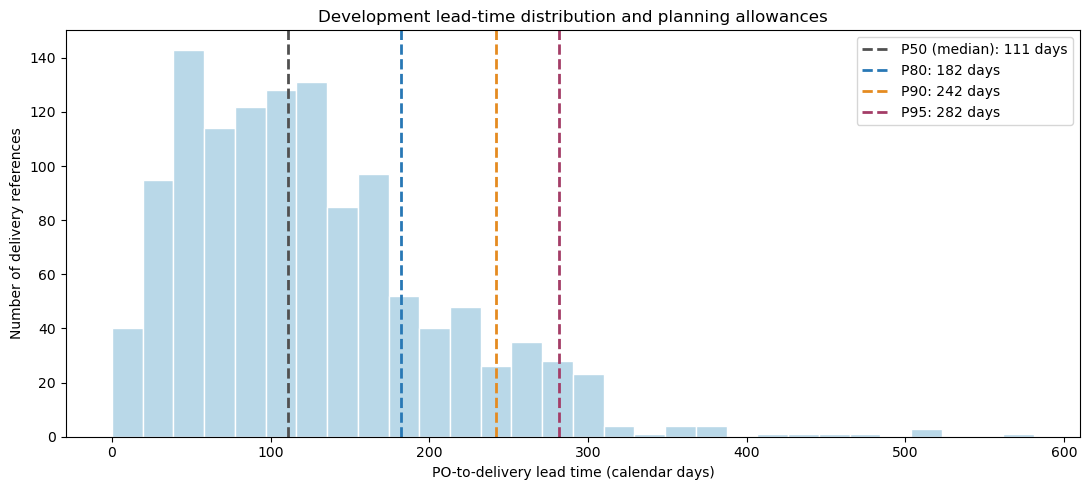

In [52]:
import matplotlib.pyplot as plt

percentiles = {
    "P50 (median)": 0.50,
    "P80": 0.80,
    "P90": 0.90,
    "P95": 0.95
}

colors = ["#505050", "#2878B5", "#E58B20", "#A43D67"]

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    df_train["lead_time_days"],
    bins=30,
    color="#B9D8E8",
    edgecolor="white"
)

for (label, percentile), color in zip(percentiles.items(), colors):
    allowance = math.ceil(
        df_train["lead_time_days"].quantile(percentile)
    )

    ax.axvline(
        allowance,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{label}: {allowance} days"
    )

ax.set(
    title="Development lead-time distribution and planning allowances",
    xlabel="PO-to-delivery lead time (calendar days)",
    ylabel="Number of delivery references"
)

ax.legend()
plt.tight_layout()
plt.show()

In [53]:
baseline_allowances = {
    "Overall median (P50)": math.ceil(
        df_train["lead_time_days"].quantile(0.50)
    ),
    "Overall mean": math.ceil(
        df_train["lead_time_days"].mean()
    ),
    "Overall 80th percentile": math.ceil(
        df_train["lead_time_days"].quantile(0.80)
    ),
    "Overall 90th percentile": math.ceil(
        df_train["lead_time_days"].quantile(0.90)
    ),
    "Overall 95th percentile": math.ceil(
        df_train["lead_time_days"].quantile(0.95)
    )
}

baseline_results = []

for rule, allowance in baseline_allowances.items():
    covered = df_test["lead_time_days"].le(allowance)

    baseline_results.append({
        "planning_rule": rule,
        "allowance_days": allowance,
        "covered_references": covered.sum(),
        "exceeding_references": (~covered).sum(),
        "validation_coverage_percent": covered.mean() * 100
    })

baseline_results = (
    pd.DataFrame(baseline_results)
    .sort_values("allowance_days")
    .reset_index(drop=True)
)

display(baseline_results.round(2))

,planning_rule,allowance_days,covered_references,exceeding_references,validation_coverage_percent
0,Overall median (P50),111,148,184,44.58
1,Overall mean,126,183,149,55.12
2,Overall 80th percentile,182,289,43,87.05
3,Overall 90th percentile,242,326,6,98.19
4,Overall 95th percentile,282,328,4,98.80


### Baseline validation findings

Five overall planning allowances were calculated from development
data and evaluated on 332 delivery references associated with
2013 orders.

- P50: 111 days, covering 44.58% of validation references.
- Mean: 126 days, covering 55.12%.
- P80: 182 days, covering 87.05%.
- P90: 242 days, covering 98.19%.
- P95: 282 days, covering 98.80%.

Moving from P80 to P90 adds 60 planning days and covers 37 additional
references. Moving from P90 to P95 adds another 40 days but covers
only two additional references.

P90 is retained as a conservative working baseline because the
additional observed coverage beyond it is small relative to the
extra allowance. P80 remains a shorter-allowance alternative.

This is a validation-based choice, not a proven optimum or an
industry service-level requirement. Inventory costs, shelf life
and the consequences of late delivery have not been quantified.
Performance on another period may differ.

### Country-level sample sizes

Check the historical evidence available for each destination before
creating country-specific allowances.

Count both delivery references and distinct orders, because one order
may contribute several deliveries. Countries with insufficient
development evidence will use the overall allowance as a fallback.

In [54]:
country_sample_sizes = pd.DataFrame({
    "development_references": df_train.groupby("country").size(),
    "development_orders": (
        df_train.groupby("country")["order_reference"].nunique()
    ),
    "validation_references": df_test.groupby("country").size()
}).fillna(0).astype(int)

display(
    country_sample_sizes
    .sort_values("validation_references", ascending=False)
)

,development_references,development_orders,validation_references
country,,,
Vietnam,283,271,68
Uganda,69,62,53
Haiti,60,56,45
Tanzania,49,41,35
Cameroon,3,3,28
Côte d'Ivoire,76,74,25
Mozambique,15,15,16
"Congo, DRC",0,0,14
Zambia,11,11,10


### Country-specific allowances and fallback

Calculate each country's 90th-percentile lead time from development
data, rounded up to whole calendar days.

Countries with at least 30 distinct development orders receive their
own allowance. Other countries use the overall P90 allowance of
242 days, including destinations absent from the development data.

The 30-order minimum is a provisional evidence threshold. It limits
reliance on very small samples but does not guarantee reliable estimates.

In [55]:
minimum_orders = 30
overall_allowance = baseline_allowances["Overall 90th percentile"]

country_p90 = (
    df_train.groupby("country")["lead_time_days"]
    .quantile(0.90)
    .apply(math.ceil)
    .rename("country_p90_days")
)

country_rules = country_sample_sizes.join(country_p90)

country_rules["use_country_rule"] = (
    country_rules["development_orders"].ge(minimum_orders)
)

country_rules["allowance_days"] = (
    country_rules["country_p90_days"]
    .where(country_rules["use_country_rule"], overall_allowance)
    .astype(int)
)

country_rules["rule_source"] = country_rules["use_country_rule"].map({
    True: "Country P90",
    False: "Overall P90 fallback"
})

display(
    country_rules[
        [
            "development_orders",
            "validation_references",
            "country_p90_days",
            "allowance_days",
            "rule_source"
        ]
    ].sort_values("validation_references", ascending=False)
)

,development_orders,validation_references,country_p90_days,allowance_days,rule_source
country,,,,,
Vietnam,271,68,165.0,165,Country P90
Uganda,62,53,98.0,98,Country P90
Haiti,56,45,197.0,197,Country P90
Tanzania,41,35,176.0,176,Country P90
Cameroon,3,28,80.0,242,Overall P90 fallback
Côte d'Ivoire,74,25,227.0,227,Country P90
Mozambique,15,16,243.0,242,Overall P90 fallback
"Congo, DRC",0,14,NaN,242,Overall P90 fallback
Zambia,11,10,151.0,242,Overall P90 fallback


### Validation of country-specific allowances

Apply the development-based country rules to 2013 validation records.
Compare coverage and average allowance with the overall 242-day baseline.

The overall fallback provides a broader estimate, but does not
guarantee adequate coverage for every destination.

In [56]:
df_validation = df_test.copy()

df_validation["allowance_days"] = (
    df_validation["country"]
    .map(country_rules["allowance_days"])
    .fillna(overall_allowance)
    .astype(int)
)

df_validation["rule_source"] = (
    df_validation["country"]
    .map(country_rules["rule_source"])
    .fillna("Overall P90 fallback")
)

df_validation["covered"] = (
    df_validation["lead_time_days"]
    .le(df_validation["allowance_days"])
)

overall_covered = df_validation["lead_time_days"].le(overall_allowance)

rule_comparison = pd.DataFrame([
    {
        "rule": "Overall P90",
        "average_allowance_days": overall_allowance,
        "covered_references": overall_covered.sum(),
        "exceeding_references": (~overall_covered).sum(),
        "coverage_percent": overall_covered.mean() * 100
    },
    {
        "rule": "Country P90 with fallback",
        "average_allowance_days": df_validation["allowance_days"].mean(),
        "covered_references": df_validation["covered"].sum(),
        "exceeding_references": (~df_validation["covered"]).sum(),
        "coverage_percent": df_validation["covered"].mean() * 100
    }
])

display(rule_comparison.round(2))

print(
    "Validation references using fallback:",
    df_validation["rule_source"].eq("Overall P90 fallback").sum()
)

,rule,average_allowance_days,covered_references,exceeding_references,coverage_percent
0,Overall P90,242.00,326,6,98.19
1,Country P90 with fallback,190.28,272,60,81.93


Validation references using fallback: 92


### Country-rule validation findings

Country-specific P90 allowances with an overall fallback reduce
the average allowance from 242 to 190.28 days.

However, validation coverage falls from 98.19% to 81.93%, and
references exceeding their allowance increase from 6 to 60.
The overall fallback is used for 92 of 332 references (27.71%).

The country rule therefore offers shorter allowances at a substantial
coverage cost. It is not adopted as a replacement for the overall
baseline at this stage. Country-level validation will identify where
the historical allowances fail to cover later observations.

In [57]:
country_validation = (
    df_validation
    .assign(
        baseline_covered=lambda data:
            data["lead_time_days"].le(overall_allowance)
    )
    .groupby("country")
    .agg(
        validation_references=("ASN/DN #", "size"),
        allowance_days=("allowance_days", "first"),
        rule_source=("rule_source", "first"),
        covered_references=("covered", "sum"),
        country_rule_coverage=("covered", "mean"),
        baseline_coverage=("baseline_covered", "mean")
    )
)

country_validation["exceeding_references"] = (
    country_validation["validation_references"]
    - country_validation["covered_references"]
)

country_validation[
    ["country_rule_coverage", "baseline_coverage"]
] *= 100

display(
    country_validation
    .sort_values("exceeding_references", ascending=False)
    .round(2)
)

,validation_references,allowance_days,rule_source,covered_references,country_rule_coverage,baseline_coverage,exceeding_references
country,,,,,,,
Vietnam,68,165,Country P90,43,63.24,95.59,25
Uganda,53,98,Country P90,28,52.83,100.00,25
Haiti,45,197,Country P90,39,86.67,97.78,6
Zimbabwe,6,242,Overall P90 fallback,5,83.33,83.33,1
South Africa,9,260,Country P90,8,88.89,88.89,1
Côte d'Ivoire,25,227,Country P90,24,96.00,100.00,1
Tanzania,35,176,Country P90,34,97.14,100.00,1
Zambia,10,242,Overall P90 fallback,10,100.00,100.00,0
South Sudan,1,242,Overall P90 fallback,1,100.00,100.00,0


### Country-level validation findings

Vietnam and Uganda account for 50 of the country rule's 60 exceedances
(83.3%).

Vietnam's 165-day allowance covers 63.24% of validation references,
while Uganda's 98-day allowance covers 52.83%. The overall 242-day
allowance covers 95.59% and 100%, respectively.

These two countries explain 47 of the 54 additional exceedances
relative to the overall baseline.

Historical country-level P90 estimates did not maintain their
nominal coverage in these validation groups. The cause remains
unresolved; changes in timing, vendor mix or product mix may contribute.

In [58]:
countries_to_review = ["Vietnam", "Uganda"]

distribution_comparison = pd.concat(
    {
        "Development": df_train,
        "Validation": df_test
    },
    names=["sample"]
).reset_index(level="sample")

distribution_comparison = (
    distribution_comparison.loc[
        distribution_comparison["country"].isin(countries_to_review)
    ]
    .groupby(["country", "sample"])
    .agg(
        delivery_references=("ASN/DN #", "size"),
        unique_orders=("order_reference", "nunique"),
        median_days=("lead_time_days", "median"),
        p90_days=("lead_time_days", lambda values: values.quantile(0.90))
    )
)

display(distribution_comparison.round(1))

delivery_references  unique_orders  median_days  p90_days
country sample                                                                
Uganda  Development                   69             62         50.0      97.2
        Validation                    53             43         91.0     150.0
Vietnam Development                  283            271        116.0     164.6
        Validation                    68             55        150.0     196.9

### Development versus validation lead times

Uganda's median lead time increases from 50 days in development
to 91 days in validation, while its P90 increases from 97.2 to
150 days.

Vietnam's median increases from 116 to 150 days, and its P90
increases from 164.6 to 196.9 days.

These distribution differences explain the reduced coverage of
the development-based country allowances. They do not establish
whether the change reflects vendor performance, product composition
or other differences between the samples.

Validation percentiles are used for diagnosis only and are not
substituted into the rules being evaluated.

In [59]:
vendor_period_data = pd.concat(
    [
        df_train.assign(sample="Development"),
        df_test.assign(sample="Validation")
    ],
    ignore_index=True
)

vendor_period_summary = (
    vendor_period_data.loc[
        vendor_period_data["country"].isin(["Uganda", "Vietnam"])
    ]
    .groupby(["country", "sample", "vendor"])
    .agg(
        delivery_references=("ASN/DN #", "size"),
        median_days=("lead_time_days", "median")
    )
)

vendor_period_summary["share_percent"] = (
    vendor_period_summary["delivery_references"]
    / vendor_period_summary.groupby(
        level=["country", "sample"]
    )["delivery_references"].transform("sum")
    * 100
)

display(
    vendor_period_summary
    .unstack("sample")
    .round(1)
)

delivery_references  \
sample                                                             Development   
country vendor                                                                   
Uganda  ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)                   13.0   
        ASPEN PHARMACARE                                                  19.0   
        Aurobindo Pharma Limited                                           6.0   
        BRISTOL-MYERS SQUIBB                                               5.0   
        CIPLA LIMITED                                                      NaN   
        EMCURE PHARMACEUTICALS LTD                                         3.0   
        HETERO LABS LIMITED                                                3.0   
        Hoffmann-La Roche ltd Basel                                        3.0   
        MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK S...                13.0   
        MICRO LABS LIMITED                                                 NaN   
        MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORAT...                 4.0   
        STRIDES ARCOLAB LIMITED                                            NaN   
Vietnam ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)                   54.0   
        Aurobindo Pharma Limited                                          71.0   
        BRISTOL-MYERS SQUIBB                                              14.0   
        CENTRAL PHARMACEUTICAL COMPANY NO. 1                               1.0   
        CIPLA LIMITED                                                     24.0   
        EMCURE PHARMACEUTICALS LTD                                         NaN   
        GILEAD SCIENCES IRELAND, INC.                                      2.0   
        HETERO LABS LIMITED                                               20.0   
        Hoffmann-La Roche ltd Basel                                        1.0   
        LAWRENCE LABORATORIES (SUBSIDIARY OF BRISTOL MY...                 1.0   
        MICRO LABS LIMITED                                                 NaN   
        MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORAT...                63.0   
        STRIDES ARCOLAB LIMITED                                           28.0   
        SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABO...                 4.0   

                                                                       \
sample                                                     Validation   
country vendor                                                          
Uganda  ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)           8.0   
        ASPEN PHARMACARE                                          5.0   
        Aurobindo Pharma Limited                                 12.0   
        BRISTOL-MYERS SQUIBB                                      NaN   
        CIPLA LIMITED                                            10.0   
        EMCURE PHARMACEUTICALS LTD                                1.0   
        HETERO LABS LIMITED                                       1.0   
        Hoffmann-La Roche ltd Basel                               NaN   
        MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK S...        NaN   
        MICRO LABS LIMITED                                        3.0   
        MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORAT...        9.0   
        STRIDES ARCOLAB LIMITED                                   4.0   
Vietnam ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)          13.0   
        Aurobindo Pharma Limited                                  7.0   
        BRISTOL-MYERS SQUIBB                                      NaN   
        CENTRAL PHARMACEUTICAL COMPANY NO. 1                      NaN   
        CIPLA LIMITED                                             2.0   
        EMCURE PHARMACEUTICALS LTD                                2.0   
        GILEAD SCIENCES IRELAND, INC.                             NaN   
        HETERO LABS LIMITED                                      20.0   
 

### Vendor composition and lead-time changes

The development and validation samples differ in vendor composition.
For example, HETERO's share of Vietnam delivery references increases
from 7.1% to 29.4%, while Aurobindo's share decreases from 25.1%
to 10.3%.

Several recurring vendors also have higher validation medians.
Vietnam's ABBVIE share remains approximately 19.1%, while its median
increases from 108.5 to 160 days. Uganda's ABBVIE and Aurobindo
medians also increase.

The country-rule coverage shortfall therefore cannot be explained
solely by the appearance of different vendors. However, these
comparisons do not isolate causes: product composition, order
characteristics and small samples may affect the results.

Adding vendor-specific rules is not automatically a solution,
because historical lead times also differ within recurring vendors.

### Sensitivity to the minimum order threshold

Compare country-specific P90 rules requiring at least 20, 30 or
50 distinct development orders. Countries below each threshold
receive the overall development P90 allowance.

Compare validation coverage, average allowance and fallback usage.
These thresholds are exploratory choices, not statistical guarantees.

In [60]:
threshold_results = []

for minimum_orders in [20, 30, 50]:
    # Determine eligibility using development evidence only.
    eligible_allowances = country_rules.loc[
        country_rules["development_orders"].ge(minimum_orders),
        "country_p90_days"
    ]

    allowances = (
        df_test["country"]
        .map(eligible_allowances)
        .fillna(overall_allowance)
        .astype(int)
    )

    covered = df_test["lead_time_days"].le(allowances)

    uses_fallback = ~df_test["country"].isin(
        eligible_allowances.index
    )

    threshold_results.append({
        "minimum_development_orders": minimum_orders,
        "average_allowance_days": allowances.mean(),
        "covered_references": covered.sum(),
        "exceeding_references": (~covered).sum(),
        "coverage_percent": covered.mean() * 100,
        "fallback_references": uses_fallback.sum()
    })

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(2))

,minimum_development_orders,average_allowance_days,covered_references,exceeding_references,coverage_percent,fallback_references
0,20,188.96,272,60,81.93,86
1,30,190.28,272,60,81.93,92
2,50,197.24,273,59,82.23,127


### Minimum-order threshold sensitivity findings

Changing the minimum development-order threshold from 20 to 30
leaves validation coverage unchanged at 81.93%.

Increasing the threshold to 50 raises the average allowance to
197.24 days but covers only one additional reference, producing
82.23% coverage.

Vietnam and Uganda qualify for country-specific allowances under
all three thresholds. Their previously identified coverage shortfalls
are therefore not addressed by these threshold changes.

The country rule's weak validation coverage is not primarily explained
by the provisional 30-order threshold. The overall P90 rule remains
the conservative baseline; country-specific rules are not adopted
as a replacement.

### Consolidated validation comparison

Compare overall allowances and country-specific rules on the same
332 validation delivery references.

Assess coverage alongside average planning allowance. Shorter allowances
do not represent measured financial savings, and higher coverage alone
does not establish an optimal rule.

In [61]:
# Five overall rules: median, mean, P80, P90 and P95.
overall_comparison = baseline_results.rename(columns={
    "planning_rule": "rule",
    "allowance_days": "average_allowance_days",
    "validation_coverage_percent": "coverage_percent"
}).copy()

# Three country rules: minimum 20, 30 or 50 development orders.
country_comparison = threshold_results.copy()

country_comparison["rule"] = (
    "Country P90 + fallback (min "
    + country_comparison["minimum_development_orders"].astype(str)
    + " orders)"
)

comparison_columns = [
    "rule",
    "average_allowance_days",
    "covered_references",
    "exceeding_references",
    "coverage_percent"
]

candidate_comparison = pd.concat(
    [
        overall_comparison[comparison_columns],
        country_comparison[comparison_columns]
    ],
    ignore_index=True
).sort_values("average_allowance_days").reset_index(drop=True)

display(candidate_comparison.round(2))

,rule,average_allowance_days,covered_references,exceeding_references,coverage_percent
0,Overall median (P50),111.00,148,184,44.58
1,Overall mean,126.00,183,149,55.12
2,Overall 80th percentile,182.00,289,43,87.05
3,Country P90 + fallback (min 20 orders),188.96,272,60,81.93
4,Country P90 + fallback (min 30 orders),190.28,272,60,81.93
5,Country P90 + fallback (min 50 orders),197.24,273,59,82.23
6,Overall 90th percentile,242.00,326,6,98.19
7,Overall 95th percentile,282.00,328,4,98.80


### Rule selection before separate-period evaluation

Select the overall development-data P90 allowance of 242 calendar
days as the conservative rule for separate-period evaluation.

It achieves 98.19% validation coverage. Increasing the allowance
to P95 adds 40 days but covers only two additional references.
The country-specific alternatives reduce average allowances but
achieve only approximately 82% coverage.

Retain the overall P80 allowance of 182 days as a pre-specified
shorter-allowance comparator.

Freeze both allowances before inspecting the separate-period results.
Neither rule is claimed to be financially optimal or an industry
service-level requirement.

### Separate-period evaluation design

Evaluate the frozen overall P90 allowance of 242 days and P80
comparator of 182 days on orders placed from January to June 2014.

This window provides more follow-up before the latest observed
delivery date than using the full 2014 order cohort.

The dataset contains observed completed deliveries. Missing,
unfinished or cancelled deliveries cannot be assessed, so coverage
is conditional on the available records.

This period has appeared in earlier exploratory summaries. It is a
separate-period check, not a fully untouched holdout.

In [62]:
final_start = pd.Timestamp("2014-01-01")
final_end = pd.Timestamp("2014-07-01")

df_final_evaluation = df_delivery_lead_time.loc[
    df_delivery_lead_time["po_date"].ge(final_start)
    & df_delivery_lead_time["po_date"].lt(final_end)
].copy()

previous_orders = set(df_train["order_reference"]) | set(
    df_test["order_reference"]
)

shared_orders = previous_orders & set(
    df_final_evaluation["order_reference"]
)

print(f"Evaluation references: {len(df_final_evaluation):,}")
print(
    "Distinct orders:",
    df_final_evaluation["order_reference"].nunique()
)
print(f"Orders shared with earlier samples: {len(shared_orders):,}")

display(
    df_final_evaluation.groupby("country")
    .agg(
        delivery_references=("ASN/DN #", "size"),
        unique_orders=("order_reference", "nunique")
    )
    .sort_values("delivery_references", ascending=False)
)

Evaluation references: 180
Distinct orders: 141
Orders shared with earlier samples: 0


,delivery_references,unique_orders
country,,
Haiti,32,26
Zimbabwe,30,16
Vietnam,29,21
Ghana,24,19
Rwanda,12,10
Uganda,12,12
Tanzania,11,11
Zambia,9,5
"Congo, DRC",7,7


### Frozen-rule evaluation: January–June 2014 orders

Evaluate the selected 242-day P90 allowance and the 182-day P80
comparator on 180 delivery references across 141 orders.

No orders overlap with the development or validation samples.
Each delivery reference receives equal weight. Allowances remain
fixed, and results describe coverage among observed completed deliveries.

In [63]:
frozen_allowances = {
    "Overall P80 comparator": 182,
    "Overall P90 selected rule": 242
}

final_results = []

for rule, allowance in frozen_allowances.items():
    covered = df_final_evaluation["lead_time_days"].le(allowance)

    final_results.append({
        "rule": rule,
        "allowance_days": allowance,
        "evaluation_references": len(df_final_evaluation),
        "covered_references": covered.sum(),
        "exceeding_references": (~covered).sum(),
        "coverage_percent": covered.mean() * 100
    })

final_results = pd.DataFrame(final_results)

display(final_results.round(2))

,rule,allowance_days,evaluation_references,covered_references,exceeding_references,coverage_percent
0,Overall P80 comparator,182,180,163,17,90.56
1,Overall P90 selected rule,242,180,176,4,97.78


### Separate-period evaluation findings

On 180 delivery references associated with January–June 2014 orders:

- The frozen 182-day P80 allowance covers 163 references (90.56%),
  with 17 exceedances.
- The frozen 242-day P90 allowance covers 176 references (97.78%),
  with four exceedances.

The additional 60 planning days cover 13 more references, increasing
coverage by 7.22 percentage points.

P90 coverage is similar across 2013 validation (98.19%) and the
separate 2014 period (97.78%). This supports its use as a conservative
scenario within this historical case study, without establishing
economic optimality or future performance.

Results remain conditional on observed completed deliveries.

In [64]:
p90_exceedances = df_final_evaluation.loc[
    df_final_evaluation["lead_time_days"].gt(242)
].copy()

p90_exceedances["days_beyond_allowance"] = (
    p90_exceedances["lead_time_days"] - 242
)

display(
    p90_exceedances[
        [
            "ASN/DN #",
            "order_reference",
            "country",
            "vendor",
            "po_date",
            "actual_delivery_date",
            "lead_time_days",
            "days_beyond_allowance"
        ]
    ].sort_values("days_beyond_allowance", ascending=False)
)

,ASN/DN #,order_reference,country,vendor,po_date,actual_delivery_date,lead_time_days,days_beyond_allowance
1232,ASN-30737,SCMS-228890,Côte d'Ivoire,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2014-03-03,2015-03-10,372,130
1233,ASN-30792,SCMS-238550,South Africa,PHARMACY DIRECT,2014-05-08,2015-02-19,287,45
1231,ASN-30715,SCMS-238570,South Africa,PHARMACY DIRECT,2014-05-08,2015-02-16,284,42
1159,ASN-29320,SCMS-228920,Côte d'Ivoire,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,2014-03-03,2014-12-04,276,34


### Exceedances of the selected allowance

Four delivery references exceed the frozen 242-day allowance:

- ASN-30737: 372 days, exceeding the allowance by 130 days.
- ASN-30792: 287 days, exceeding it by 45 days.
- ASN-30715: 284 days, exceeding it by 42 days.
- ASN-29320: 276 days, exceeding it by 34 days.

These represent four distinct orders. Two references are in
Côte d'Ivoire and two are in South Africa.

Despite 97.78% overall coverage, coverage is 5 of 7 references
(71.43%) for Côte d'Ivoire and 1 of 3 (33.33%) for South Africa.
These small samples limit generalisation but demonstrate that
strong aggregate coverage can hide destination-level shortfalls.

The allowances remain unchanged after this evaluation. Exceedances
refer to the planning allowance, not necessarily the recorded schedule.

## 10. Order-by-Date Scenario Calculator

Calculate an order-by date by subtracting a planning allowance
from a user-specified required delivery date.

Two historical scenarios are available:
- Shorter allowance: 182 calendar days, based on development P80.
- Conservative allowance: 242 calendar days, based on development P90.

These overall allowances apply to the Direct Drop ARV case study.
Historical coverage describes observed delivery references, not
a guaranteed probability of meeting a future delivery date.

The calculator does not account for weekends, holidays, stock levels,
shelf life or supplier-specific constraints.

In [65]:
def calculate_order_by_dates(required_delivery_date):
    # Require an unambiguous YYYY-MM-DD input.
    required_date = pd.to_datetime(
        required_delivery_date,
        format="%Y-%m-%d",
        errors="raise"
    )

    if pd.isna(required_date):
        raise ValueError("Enter a valid delivery date in YYYY-MM-DD format.")

    scenarios = [
        ("Shorter allowance (P80)", 182),
        ("Conservative allowance (P90)", 242)
    ]

    results = []

    for scenario, allowance in scenarios:
        order_by_date = required_date - pd.Timedelta(days=allowance)

        validation_coverage = (
            df_test["lead_time_days"].le(allowance).mean() * 100
        )

        separate_period_coverage = (
            df_final_evaluation["lead_time_days"]
            .le(allowance).mean() * 100
        )

        results.append({
            "scenario": scenario,
            "required_delivery_date": required_date.date(),
            "allowance_days": allowance,
            "order_by_date": order_by_date.date(),
            "2013_coverage_percent": validation_coverage,
            "2014_H1_coverage_percent": separate_period_coverage
        })

    return pd.DataFrame(results).round(2)

In [66]:
import ipywidgets as widgets
from IPython.display import display, clear_output

delivery_date_picker = widgets.DatePicker(
    description="Delivery date:",
    style={"description_width": "initial"}
)

calculate_button = widgets.Button(
    description="Calculate order dates",
    button_style="primary",
    icon="calendar",
    layout=widgets.Layout(width="210px")
)

calculator_output = widgets.Output()

def show_order_dates(_):
    with calculator_output:
        clear_output(wait=True)

        selected_date = delivery_date_picker.value

        if selected_date is None:
            print("Please select a required delivery date.")
            return

        results = calculate_order_by_dates(selected_date.isoformat())

        display(
            results.rename(columns={
                "scenario": "Scenario",
                "required_delivery_date": "Required delivery",
                "allowance_days": "Allowance (days)",
                "order_by_date": "Order by",
                "2013_coverage_percent": "2013 coverage (%)",
                "2014_H1_coverage_percent": "2014 H1 coverage (%)"
            }).style.hide(axis="index")
        )

        print(
            "Historical scenarios for Direct Drop ARV deliveries. "
            "Dates use calendar days and do not guarantee delivery."
        )

calculate_button.on_click(show_order_dates)

display(
    widgets.VBox([
        widgets.HTML("<b>Procurement order-by-date calculator</b>"),
        delivery_date_picker,
        calculate_button,
        calculator_output
    ])
)

In [67]:
display(calculate_order_by_dates("2027-06-30"))

,scenario,required_delivery_date,allowance_days,order_by_date,2013_coverage_percent,2014_H1_coverage_percent
0,Shorter allowance (P80),2027-06-30,182,2026-12-30,87.05,90.56
1,Conservative allowance (P90),2027-06-30,242,2026-10-31,98.19,97.78


### Calculator example

For a required delivery date of 30 June 2027, the 182-day scenario
returns 30 December 2026 and the 242-day scenario returns
31 October 2026.

The conservative scenario requires ordering 60 days earlier.
Historical coverage is displayed alongside each scenario to make
the allowance–coverage trade-off visible.

The example demonstrates date arithmetic using historical allowances,
not a current operational recommendation.

## 11. Tableau Data Exports

Export analytical datasets at clearly defined levels of detail.

The delivery-reliability dataset contains one source product line
per row. It includes both Direct Drop and From RDC ARV records,
with recorded dates, delivery delay and delivery status.

Line-level metrics and reference-level metrics will be labelled
separately in Tableau.

In [68]:
from pathlib import Path

# Save alongside the project's other outputs.
tableau_folder = data_path.parent.parent / "outputs" / "tableau"
tableau_folder.mkdir(parents=True, exist_ok=True)

reliability_columns = [
    "ID",
    "PO / SO #",
    "ASN/DN #",
    "Country",
    "Fulfill Via",
    "Vendor",
    "Sub Classification",
    "Item Description",
    "Shipment Mode",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "delivery_delay_days",
    "delivery_status",
    "recorded_before_delivery"
]

tableau_reliability = df_arv_delivery[reliability_columns].copy()

export_path = tableau_folder / "arv_delivery_reliability.csv"

tableau_reliability.to_csv(
    export_path,
    index=False,
    date_format="%Y-%m-%d",
    encoding="utf-8-sig"
)

print(f"Exported rows: {len(tableau_reliability):,}")
print(f"Unique row IDs: {tableau_reliability['ID'].nunique():,}")
print(f"Saved to: {export_path}")

Exported rows: 8,546
Unique row IDs: 8,546
Saved to: /Users/dyuthibopparaju/Desktop/Procurement Lead-Time Risk for HIV Medicines/outputs/tableau/arv_delivery_reliability.csv


In [69]:
lead_time_columns = [
    "ASN/DN #",
    "order_reference",
    "country",
    "vendor",
    "po_date",
    "actual_delivery_date",
    "lead_time_days"
]

tableau_lead_time = df_delivery_lead_time[lead_time_columns].copy()

tableau_lead_time["zero_day_flag"] = (
    tableau_lead_time["lead_time_days"].eq(0)
)

tableau_folder = data_path.parent.parent / "outputs" / "tableau"
tableau_folder.mkdir(parents=True, exist_ok=True)

export_path = tableau_folder / "arv_procurement_lead_time.csv"

tableau_lead_time.to_csv(
    export_path,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print(f"Exported delivery references: {len(tableau_lead_time):,}")
print(
    "Unique delivery references:",
    f'{tableau_lead_time["ASN/DN #"].nunique():,}'
)
print(f"Saved to: {export_path}")

Exported delivery references: 2,085
Unique delivery references: 2,085
Saved to: /Users/dyuthibopparaju/Desktop/Procurement Lead-Time Risk for HIV Medicines/outputs/tableau/arv_procurement_lead_time.csv


## 12. Conclusions and Limitations

### Main findings

- Among 2,085 eligible Direct Drop ARV delivery references, median
  procurement lead time was 115 calendar days and historical P90
  was 224 days.
- Long lead times did not necessarily mean late delivery. The five
  longest intervals matched their recorded scheduled dates.
- Across 8,546 ARV product lines, 95.60% of Direct Drop lines and
  82.26% of From RDC lines arrived on or before their recorded
  scheduled dates. These are descriptive comparisons, not evidence
  that fulfilment method caused the difference.

### Planning scenarios

The development-based allowance of 242 calendar days covered 98.19%
of 2013 validation references and 97.78% of January–June 2014
evaluation references.

The shorter 182-day allowance covered 87.05% and 90.56%, respectively.
These scenarios make the trade-off between planning time and
historical coverage visible.

Country-specific P90 rules achieved approximately 82% validation
coverage and were not adopted as a replacement for the overall rule.

### Limitations

- Results describe observed completed deliveries in historical data;
  missing, unfinished and cancelled deliveries cannot be assessed.
- Recorded scheduled dates may differ from original commitments.
- Zero-day observations remain flagged and retained; some vendor
  summaries are sensitive to their inclusion.
- Multiple delivery references may belong to one order, so
  reference-level results give more weight to orders with more deliveries.
- The separate evaluation period appeared in earlier exploratory
  analysis and is not a fully untouched holdout.
- Inventory costs, shelf life and the consequences of late delivery
  were not quantified. The allowances are historical planning
  scenarios, not proven optimal rules or guarantees of future delivery.

### Deliverables

Two Tableau dashboards present delivery reliability and procurement
lead-time planning. The calculator translates the historical
allowances into illustrative order-by dates.